## Colab specifics

In [1]:
!pip install -q \
  "torch==2.4.1" \
  "torchvision==0.19.1" \
  "transformers==4.44.2" \
  "matplotlib==3.9.2"

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import shutil
import os
from zipfile import ZipFile

In [4]:
destination_folder = 'data/'
drive_folder = '/content/drive/MyDrive/Deep_Learning/'

shutil.copytree(drive_folder, destination_folder, dirs_exist_ok=True)
shutil.rmtree('sample_data', ignore_errors=True, onerror=None)
os.mkdir("src")

In [5]:
def unzipAndDelete(zipName):
    extract_dir = os.path.dirname(os.path.abspath(zipName))
    with ZipFile(zipName, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    os.remove(zipName)
    shutil.rmtree(extract_dir + '/__MACOSX', ignore_errors=True, onerror=None)

In [6]:
unzipAndDelete('/content/data/celeba.zip')

## Imports

In [7]:
import json
from math import inf
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torchvision.datasets import CelebA
from transformers import CLIPModel, CLIPProcessor
import pandas as pd
from IPython.display import display


In [8]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE


'cuda'

## Embedding CelebA images using CLIP

### Experiments

In [9]:
data_root = Path("./data")
Path.exists(data_root)

True

In [10]:
celeba = CelebA(root=data_root, split="test", download=False)
len(celeba)

19962

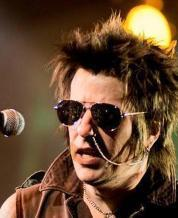

In [11]:
celeba[10][0]

Load CLIP from huggingface

In [12]:
CLIP_VERSION = "openai/clip-vit-base-patch32"

model = CLIPModel.from_pretrained(CLIP_VERSION)
model = model.to(DEVICE)
model.eval()

processor = CLIPProcessor.from_pretrained(CLIP_VERSION)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


Lets try to embed a few images using it

In [13]:
imgs = [celeba[idx][0] for idx in range(2)]
imgs

[<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=178x218>,
 <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=178x218>]

In [14]:
inputs = processor(images=imgs, return_tensors="pt")
inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

inputs["pixel_values"].shape


torch.Size([2, 3, 224, 224])

In [15]:
with torch.inference_mode():
    img_embeds = model.get_image_features(pixel_values=inputs["pixel_values"])

img_embeds.shape

torch.Size([2, 512])

In [16]:
# `get_image_features` already returns the embedding tensor.
# Showing the tensor shape is the correct sanity check here.
img_embeds.shape


torch.Size([2, 512])

worth L2-normalising embeds before saving so cosine similarity becomes a plain dot product later.

In [17]:
img_embeds = F.normalize(img_embeds, p=2, dim=-1)
img_embeds.shape


torch.Size([2, 512])

In [18]:
img_embeds

tensor([[ 0.0401,  0.0096, -0.0243,  ...,  0.0700,  0.0218, -0.0172],
        [ 0.0234,  0.0097, -0.0136,  ...,  0.0202, -0.0179,  0.0309]],
       device='cuda:0')

In [19]:
img_embeds[0].norm()

tensor(1., device='cuda:0')

normalization worked; vector length = 1

In [20]:
torch.save(img_embeds, "./src/sample_db.pt")

### Tests

In [21]:
def embed_celeba_imgs(num_imgs, batch_size=128):
    """Embed CelebA test images using CLIP's image tower."""

    batches = []

    for cutoff in range(0, num_imgs, batch_size):
        imgs = [celeba[idx][0] for idx in range(cutoff, min(cutoff + batch_size, num_imgs))]
        inputs = processor(images=imgs, return_tensors="pt")
        pixel_values = inputs["pixel_values"].to(DEVICE)

        with torch.inference_mode():
            embeddings = model.get_image_features(pixel_values=pixel_values)
            embeddings = F.normalize(embeddings, p=2, dim=-1)
            batches.append(embeddings)

    return torch.cat(batches, dim=0)


In [22]:
db = embed_celeba_imgs(num_imgs=len(celeba))
db.shape

torch.Size([19962, 512])

Looks good, all 19k images embedded

In [23]:
torch.save(db, "./src/db.pt")

## Extending to CelebA attributes

Lets focus on the attributes that we need to condition the image embeddings on
- CLIP was trained on natural language captions like "a photo of a ____ ."
- From the CLAY and GDE literature, they just embed the attribute as positive text and let the +/− sign in the arithmetic carry the polarity.
- We will adopt the same approach, and hopefully have a clean baseline that isn't influenced by some prompt engineering tricks.

Lets embed all 40 celeba attributes, similar to the images approach. then we will reference it on demand during the query computation

In [24]:
def embed_image_batch(pixel_values):
    with torch.inference_mode():
        embeddings = model.get_image_features(pixel_values=pixel_values)
    return F.normalize(embeddings, p=2, dim=-1)


def embed_text_batch(text_inputs):
    with torch.inference_mode():
        embeddings = model.get_text_features(**text_inputs)
    return F.normalize(embeddings, p=2, dim=-1)


In [25]:
def embed_images(batch_size=128):
    """Embed the full CelebA test split."""

    num_imgs = len(celeba)
    batches = []

    for cutoff in range(0, num_imgs, batch_size):
        imgs = [celeba[idx][0] for idx in range(cutoff, min(cutoff + batch_size, num_imgs))]
        inputs = processor(images=imgs, return_tensors="pt")
        pixel_values = inputs["pixel_values"].to(DEVICE)

        embeddings = embed_image_batch(pixel_values)
        batches.append(embeddings)

    return torch.cat(batches, dim=0)


In [26]:
print(celeba.attr_names)

['5_o_Clock_Shadow', 'Arched_Eyebrows', 'Attractive', 'Bags_Under_Eyes', 'Bald', 'Bangs', 'Big_Lips', 'Big_Nose', 'Black_Hair', 'Blond_Hair', 'Blurry', 'Brown_Hair', 'Bushy_Eyebrows', 'Chubby', 'Double_Chin', 'Eyeglasses', 'Goatee', 'Gray_Hair', 'Heavy_Makeup', 'High_Cheekbones', 'Male', 'Mouth_Slightly_Open', 'Mustache', 'Narrow_Eyes', 'No_Beard', 'Oval_Face', 'Pale_Skin', 'Pointy_Nose', 'Receding_Hairline', 'Rosy_Cheeks', 'Sideburns', 'Smiling', 'Straight_Hair', 'Wavy_Hair', 'Wearing_Earrings', 'Wearing_Hat', 'Wearing_Lipstick', 'Wearing_Necklace', 'Wearing_Necktie', 'Young', '']


In [27]:
celeba.attr.shape[1], len(celeba.attr_names)

(40, 41)

there is a wierd behaviour where CelebA dataloader returns 41 attributes instead of 40. the last one is an empty string. we'll take this into account when retrieving the attributes

In [28]:
def embed_attributes(batch_size=40):
    prompts = [f"a portrait of a person with {attribute.replace('_', ' ').lower()}" for attribute in celeba.attr_names[:40]]
    batches = []

    for cutoff in range(0, len(prompts), batch_size):
        text_batch = prompts[cutoff : cutoff + batch_size]
        inputs = processor(text=text_batch, return_tensors="pt", padding=True, truncation=True)
        text_inputs = {key: value.to(DEVICE) for key, value in inputs.items()}
        batches.append(embed_text_batch(text_inputs))

    return torch.cat(batches, dim=0)


In [29]:
text_db = embed_attributes()
text_db.shape

torch.Size([40, 512])

In [30]:
torch.save(text_db, "./src/text_db.pt")

## Exploring the evaluation data

In [31]:
annotations_path = Path("./data/celeba_evaluation.json")
annotations_path.exists()

True

In [32]:
with open(annotations_path, "r") as f:
    annotations = json.load(f)

len(annotations)

14

In [33]:
for annotation in annotations:
    desc = annotation["query"]
    refs = annotation["ground_truth"].keys()
    print(f"{desc} | {len(refs)}")

+Smiling | 4786
+Eyeglasses | 2196
-Heavy_Makeup | 4087
+Male | 1595
-Young | 5355
+Blond_Hair | 5469
+Mustache | 301
-Young | 5355
+Eyeglasses, +Smiling | 612
+Black_Hair, -Wavy_Hair | 2572
-Male, -Mustache | 27
+Chubby, -Young | 584
-Smiling, +Eyeglasses, +Wearing_Hat | 79
+Wearing_Lipstick, -Heavy_Makeup, +Smiling | 34


Notice some queries have very many reference images while others like `-Male, -Mustache` only have 27.

## Computing a baseline

we know that each query is eval file is structured like so:
```json
{
    query: "+attribute, -attribute",
    ground_truth: {
        [ref-img-idx]: [similar-img-idx-1, similar-img-idx-2...]
        [ref-img-idx]: [similar-img-idx-1, similar-img-idx-2...]
        ...
    }
}
```
For a baseline, we can compose the query embedding by adding/subtructing attribute embeddings like so:
`q = v_ref + Σ attrtibuts⁺ − Σ attributes⁻`

we can try:
- Parse "+attribute, -attribute" into separate lists, retrive their embedding representations, sum up each list.
- For each ref image in query's ground_truth:
    - Compose q as shown above
    - Cosine similarity between q and all 19k img embeds
    - Rank in descending order, take top-K
    - Evaluate: Recall@K, Precision@K for K in {1, 5, 10}
- Average the results. maybe we can explore better aggregation techiniques later

### Experiments

In [34]:
img_db = torch.load("./src/db.pt", map_location=DEVICE).to(DEVICE)
text_db = torch.load("./src/text_db.pt", map_location=DEVICE).to(DEVICE)

img_db.shape, text_db.shape


/tmp/ipykernel_4059/3018291695.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  img_db = torch.load("./src/db.pt", map_location=DEVICE).to(DEVICE)
/tmp/ipykernel_4059/301

(torch.Size([19962, 512]), torch.Size([40, 512]))

Loading our dbs works fine

In [35]:
for annotation in annotations:
    desc = annotation["query"]
    refs = annotation["ground_truth"].keys()
    print(f"{desc} | {len(refs)}")

+Smiling | 4786
+Eyeglasses | 2196
-Heavy_Makeup | 4087
+Male | 1595
-Young | 5355
+Blond_Hair | 5469
+Mustache | 301
-Young | 5355
+Eyeglasses, +Smiling | 612
+Black_Hair, -Wavy_Hair | 2572
-Male, -Mustache | 27
+Chubby, -Young | 584
-Smiling, +Eyeglasses, +Wearing_Hat | 79
+Wearing_Lipstick, -Heavy_Makeup, +Smiling | 34


Lets create our helper functions

In [36]:
attribute2idx = {name: idx for idx, name in enumerate(celeba.attr_names[:40])}
attribute2idx

{'5_o_Clock_Shadow': 0,
 'Arched_Eyebrows': 1,
 'Attractive': 2,
 'Bags_Under_Eyes': 3,
 'Bald': 4,
 'Bangs': 5,
 'Big_Lips': 6,
 'Big_Nose': 7,
 'Black_Hair': 8,
 'Blond_Hair': 9,
 'Blurry': 10,
 'Brown_Hair': 11,
 'Bushy_Eyebrows': 12,
 'Chubby': 13,
 'Double_Chin': 14,
 'Eyeglasses': 15,
 'Goatee': 16,
 'Gray_Hair': 17,
 'Heavy_Makeup': 18,
 'High_Cheekbones': 19,
 'Male': 20,
 'Mouth_Slightly_Open': 21,
 'Mustache': 22,
 'Narrow_Eyes': 23,
 'No_Beard': 24,
 'Oval_Face': 25,
 'Pale_Skin': 26,
 'Pointy_Nose': 27,
 'Receding_Hairline': 28,
 'Rosy_Cheeks': 29,
 'Sideburns': 30,
 'Smiling': 31,
 'Straight_Hair': 32,
 'Wavy_Hair': 33,
 'Wearing_Earrings': 34,
 'Wearing_Hat': 35,
 'Wearing_Lipstick': 36,
 'Wearing_Necklace': 37,
 'Wearing_Necktie': 38,
 'Young': 39}

In [37]:
def sum_up(attributes):
    if len(attributes) > 0:
        # retrieve their embedding representations from db
        # when we slice from db we get (512,); lets make it (1,512) using unsqueeze
        embeds = [text_db[attribute2idx[attr]].unsqueeze(0) for attr in attributes]
        # concatenete then sum up all +ve embeds, same for -ve
        result = torch.sum(torch.cat(embeds, 0), 0, keepdim=True)
        return result
    return torch.zeros((1, text_db.shape[-1]), dtype=text_db.dtype, device=DEVICE)


In [38]:
from math import inf


def compute_similarity(query, db, ref_idx, k=10):
    # (19k,512)*(512,1)
    score = db @ query.T

    # modify the score of ref_img to eliminate it from top-k
    score[ref_idx] = -inf
    sorted_scores, img_idxs = torch.sort(score, dim=0, descending=True)
    top_k = (torch.flatten(img_idxs[:k])).tolist()

    # print('scores',score[:5])
    # print('-'*20)
    # print('sorted_scores',sorted_scores[:5])
    # print('-'*20)
    # print('img_idxs',img_idxs[:5])
    # print('-'*20)

    return top_k

In [39]:
def evaluate_retrieval(retrieved_indices: list[int], ground_truth_indices: list[int], k: int, log: bool = True) -> dict:
    """
    Evaluate the retrieval performance for a single source image.

    Args:
    ----
        retrieved_indices: list of image IDs predicted by the model,
            ordered by similarity (descending).
        ground_truth_indices: list of valid target IDs from the benchmark JSON.
        k: the cutoff for top-K evaluation (e.g., 1, 5, 10).

    Return:
    ------
        A dictionary containing Recall@K and Precision@K.

    """
    if log:
        print(f"retrieved={retrieved_indices[:k]}")
        print(f"truth={ground_truth_indices[:k]}")

    # Isolate the top K predictions
    top_k_retrieved = retrieved_indices[:k]

    # Calculate the intersection between predictions and ground truth
    hits = set(top_k_retrieved).intersection(set(ground_truth_indices))
    num_hits = len(hits)

    # Metrics calculations
    # Recall@K (Hit Rate): 1 if at least one match is found, 0 otherwise
    recall_at_k = 1 if num_hits > 0 else 0

    # Precision@K: Fraction of top K predictions that are correct
    precision_at_k = num_hits / k

    return {f"Recall@{k}": recall_at_k, f"Precision@{k}": precision_at_k}

In [40]:
def run_eval(annotation):
    # split annotation string into invididual attributes
    attributes = annotation["query"].split(",")
    attributes = [attr.strip() for attr in attributes]

    # isolate the +ve and -ve attributes
    positive_attributes = []
    negative_attributes = []
    for attribute in attributes:
        if attribute[0] == "+":
            positive_attributes.append(attribute[1:])
        elif attribute[0] == "-":
            negative_attributes.append(attribute[1:])

    # sum up each set
    positive_attributes = sum_up(positive_attributes)
    negative_attributes = sum_up(negative_attributes)

    # retrieve all the image reference for the query
    refs = [int(value) for value in list(annotation["ground_truth"].keys())]

    for idx in refs[:1]:  # lets test for just 1 reference image
        # get embedding representation
        img_embed = img_db[idx]

        # apply naive addition and subtruction of the  attributes to the img embed
        # q = v_ref + Σ [+]attr - Σ [-]attr
        query = img_embed + positive_attributes - negative_attributes

        top_10 = compute_similarity(query, img_db, idx)

        # score perfomance
        ground_truths = annotation["ground_truth"][str(idx)]

        for cutoff in [1, 5, 10]:
            result = evaluate_retrieval(top_10, ground_truths, cutoff, log=True)
            print(result)
            print("-" * 50)

In [41]:
# lets test it for just 1 iteration
for annotation in annotations[:1]:
    run_eval(annotation)

retrieved=[13877]
truth=[325]
{'Recall@1': 0, 'Precision@1': 0.0}
--------------------------------------------------
retrieved=[13877, 16927, 14315, 4868, 10996]
truth=[325, 456, 579, 685, 763]
{'Recall@5': 0, 'Precision@5': 0.0}
--------------------------------------------------
retrieved=[13877, 16927, 14315, 4868, 10996, 11778, 17961, 3874, 7357, 3025]
truth=[325, 456, 579, 685, 763, 893, 981, 1363, 1646, 2142]
{'Recall@10': 0, 'Precision@10': 0.0}
--------------------------------------------------


In [42]:
annotations[0]["query"], list(annotations[0]["ground_truth"].keys())[0]

('+Smiling', '13')

for this single iteration using the first query "+Smiling" and only 1 ref image, we get no hits. lets visually inspect the results

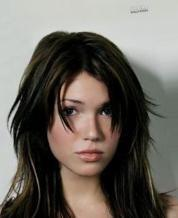

In [43]:
celeba[13][0]

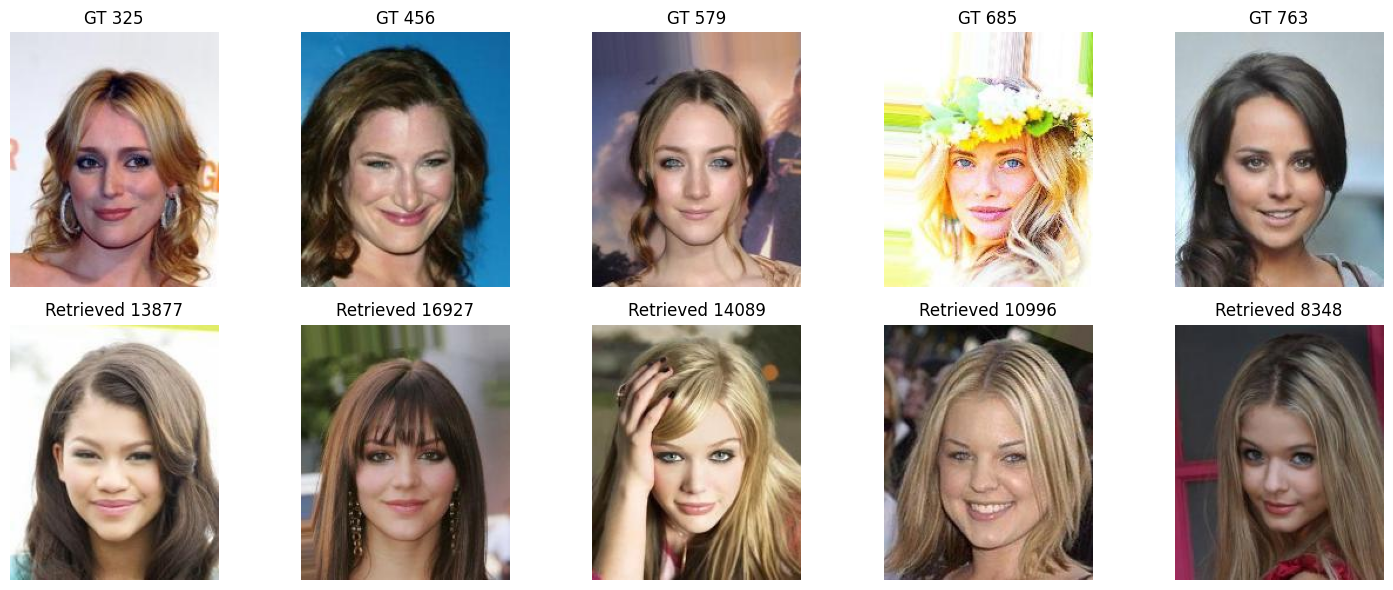

In [44]:
retrieved = [13877, 16927, 14089, 10996, 8348]
ground_truth = [325, 456, 579, 685, 763]

fig, axes = plt.subplots(2, len(retrieved), figsize=(15, 6))
for col, (gt, rt) in enumerate(zip(ground_truth, retrieved)):
    axes[0, col].imshow(celeba[gt][0])
    axes[0, col].set_title(f"GT {gt}")
    axes[0, col].axis("off")

    axes[1, col].imshow(celeba[rt][0])
    axes[1, col].set_title(f"Retrieved {rt}")
    axes[1, col].axis("off")

axes[0, 0].set_ylabel("Ground truth")
axes[1, 0].set_ylabel("Retrieved")
plt.tight_layout()
plt.show()

at least all retrieved imgs are women and seem to be smiling.

The fact that none of them happen to be in the ground-truth set is expected: ground truth requires Hamming ≤ 2 on all 40 attributes, which is a much tighter constraint than just "smiling woman".

we will get more insights on perfonce by running the eval on the entire annotation set and aggregating results. lets work on the aggregation logic:

- lets start simple, we'll compute the avg of each k metric(recall, precision) for each query, across all reference imgs.
- we can track totals like so
```json
{
  "+Smiling": {"ref_counts": 50 ,"Recall@1": 0.05, "Precision@1": 0.05, "Recall@5": 0.12, ...},
  "+Eyeglasses": {"ref_counts": 1000, "Recall@1": 0.08, ...},
}
```
- then compute avg at the end using img ref counts

In [45]:
def initialize_scores():
    scores = {}
    for annotation in annotations:
        attributes = annotation["query"]
        refs = annotation["ground_truth"].keys()
        scores[attributes] = {"ref_counts": len(refs)}

        for k in [1, 5, 10]:
            recall = f"Recall@{k}"
            precision = f"Precision@{k}"
            scores[attributes][recall] = 0
            scores[attributes][precision] = 0

    return scores

In [46]:
scores = initialize_scores()
scores

{'+Smiling': {'ref_counts': 4786,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Eyeglasses': {'ref_counts': 2196,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '-Heavy_Makeup': {'ref_counts': 4087,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Male': {'ref_counts': 1595,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '-Young': {'ref_counts': 5355,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Blond_Hair': {'ref_counts': 5469,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Mustache': {'ref_counts': 301,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0

In [47]:
def log(result, query, k):
    # result example: {"Recall@1": 0, "Precision@2": 0}
    recall = f"Recall@{k}"
    precision = f"Precision@{k}"

    scores[query][recall] += result[recall]
    scores[query][precision] += result[precision]

update the eval function with the new `log` function

In [48]:
def run_eval(annotation):
    # split annotation string into invididual attributes
    attributes = annotation["query"].split(",")
    attributes = [attr.strip() for attr in attributes]

    # isolate the +ve and -ve attributes
    positive_attributes = []
    negative_attributes = []
    for attribute in attributes:
        if attribute[0] == "+":
            positive_attributes.append(attribute[1:])
        elif attribute[0] == "-":
            negative_attributes.append(attribute[1:])

    # sum up each set
    positive_attributes = sum_up(positive_attributes)
    negative_attributes = sum_up(negative_attributes)

    # retrieve all the image reference for the query
    refs = [int(value) for value in list(annotation["ground_truth"].keys())]

    for idx in refs:
        # get embedding representation
        img_embed = img_db[idx]

        # apply naive addition and subtruction of the  attributes to the img embed
        # q = v_ref + Σ [+]attr - Σ [-]attr
        query = img_embed + positive_attributes - negative_attributes

        top_10 = compute_similarity(query, img_db, idx)

        # score perfomance
        ground_truths = annotation["ground_truth"][str(idx)]

        for k in [1, 5, 10]:
            # result struct: {"Recall@k": 0, "Precision@k": 0}
            result = evaluate_retrieval(top_10, ground_truths, k, log=False)
            log(result, annotation["query"], k)

In [49]:
# lets test it for just 1 query, all refs
for annotation in annotations[:1]:
    run_eval(annotation)

In [50]:
scores

{'+Smiling': {'ref_counts': 4786,
  'Recall@1': 298,
  'Precision@1': 298.0,
  'Recall@5': 875,
  'Precision@5': 229.39999999999816,
  'Recall@10': 1240,
  'Precision@10': 192.09999999999678},
 '+Eyeglasses': {'ref_counts': 2196,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '-Heavy_Makeup': {'ref_counts': 4087,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Male': {'ref_counts': 1595,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '-Young': {'ref_counts': 5355,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Blond_Hair': {'ref_counts': 5469,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Mustache': {'ref_counts': 301,
  'Recall@1': 0,
  'Precisi

In [51]:
def compute_averages(scores):
    avg_scores = {}
    for query in scores.keys():
        avg_scores[query] = {}
        counts = scores[query]["ref_counts"]
        for k in [1, 5, 10]:
            avg_scores[query][f"Recall@{k}"] = round((scores[query][f"Recall@{k}"] / counts), 4)
            avg_scores[query][f"Precision@{k}"] = round((scores[query][f"Precision@{k}"] / counts), 4)

    return avg_scores

In [52]:
averages = compute_averages(scores)
averages

{'+Smiling': {'Recall@1': 0.0623,
  'Precision@1': 0.0623,
  'Recall@5': 0.1828,
  'Precision@5': 0.0479,
  'Recall@10': 0.2591,
  'Precision@10': 0.0401},
 '+Eyeglasses': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '-Heavy_Makeup': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '+Male': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '-Young': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '+Blond_Hair': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '+Mustache': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '+Eyegla

- for each of the 4786 ref images we used to retrieve similar embeddings from the db, only ~6.5% were the first in the list.
- Random chance would be much lower (≈ |ground truth| / 19962), so the baseline is doing better than guessing. This is strenghtened by the fact that CLIP's image embeddings already capture some attribute structure, and naïve vector arithmetic nudges the query in roughly the right direction. But it's far from accurate retrieval.
- lets test this flow using the full eval set

### Tests

In [53]:
# reset scores
scores = initialize_scores()

In [54]:
# lets run the full pipeline
for annotation in annotations:
    run_eval(annotation)

In [55]:
scores

{'+Smiling': {'ref_counts': 4786,
  'Recall@1': 298,
  'Precision@1': 298.0,
  'Recall@5': 875,
  'Precision@5': 229.39999999999816,
  'Recall@10': 1240,
  'Precision@10': 192.09999999999678},
 '+Eyeglasses': {'ref_counts': 2196,
  'Recall@1': 36,
  'Precision@1': 36.0,
  'Recall@5': 161,
  'Precision@5': 37.19999999999995,
  'Recall@10': 251,
  'Precision@10': 33.600000000000094},
 '-Heavy_Makeup': {'ref_counts': 4087,
  'Recall@1': 117,
  'Precision@1': 117.0,
  'Recall@5': 380,
  'Precision@5': 88.00000000000054,
  'Recall@10': 578,
  'Precision@10': 73.00000000000027},
 '+Male': {'ref_counts': 1595,
  'Recall@1': 10,
  'Precision@1': 10.0,
  'Recall@5': 22,
  'Precision@5': 5.8000000000000025,
  'Recall@10': 29,
  'Precision@10': 4.2},
 '-Young': {'ref_counts': 5355,
  'Recall@1': 102,
  'Precision@1': 102.0,
  'Recall@5': 302,
  'Precision@5': 70.80000000000037,
  'Recall@10': 520,
  'Precision@10': 68.80000000000031},
 '+Blond_Hair': {'ref_counts': 5469,
  'Recall@1': 135,
  'Pre

In [56]:
averages = compute_averages(scores)
averages

{'+Smiling': {'Recall@1': 0.0623,
  'Precision@1': 0.0623,
  'Recall@5': 0.1828,
  'Precision@5': 0.0479,
  'Recall@10': 0.2591,
  'Precision@10': 0.0401},
 '+Eyeglasses': {'Recall@1': 0.0164,
  'Precision@1': 0.0164,
  'Recall@5': 0.0733,
  'Precision@5': 0.0169,
  'Recall@10': 0.1143,
  'Precision@10': 0.0153},
 '-Heavy_Makeup': {'Recall@1': 0.0286,
  'Precision@1': 0.0286,
  'Recall@5': 0.093,
  'Precision@5': 0.0215,
  'Recall@10': 0.1414,
  'Precision@10': 0.0179},
 '+Male': {'Recall@1': 0.0063,
  'Precision@1': 0.0063,
  'Recall@5': 0.0138,
  'Precision@5': 0.0036,
  'Recall@10': 0.0182,
  'Precision@10': 0.0026},
 '-Young': {'Recall@1': 0.019,
  'Precision@1': 0.019,
  'Recall@5': 0.0564,
  'Precision@5': 0.0132,
  'Recall@10': 0.0971,
  'Precision@10': 0.0128},
 '+Blond_Hair': {'Recall@1': 0.0247,
  'Precision@1': 0.0247,
  'Recall@5': 0.0819,
  'Precision@5': 0.0216,
  'Recall@10': 0.1267,
  'Precision@10': 0.0193},
 '+Mustache': {'Recall@1': 0.0664,
  'Precision@1': 0.0664,
 

In [57]:
def visualize_results():
    queries = list(averages.keys())
    metrics = ["Recall@1", "Recall@5", "Recall@10", "Precision@1", "Precision@5", "Precision@10"]
    x = np.arange(len(queries))
    w = 0.13

    fig, ax = plt.subplots(figsize=(14, 6))
    for i, m in enumerate(metrics):
        ax.bar(x + i * w, [averages[q][m] for q in queries], w, label=m)

    ax.set_xticks(x + w * 2.5)
    ax.set_xticklabels(queries, rotation=45, ha="right")
    ax.set_ylabel("Score")
    ax.legend()
    plt.tight_layout()
    plt.show()

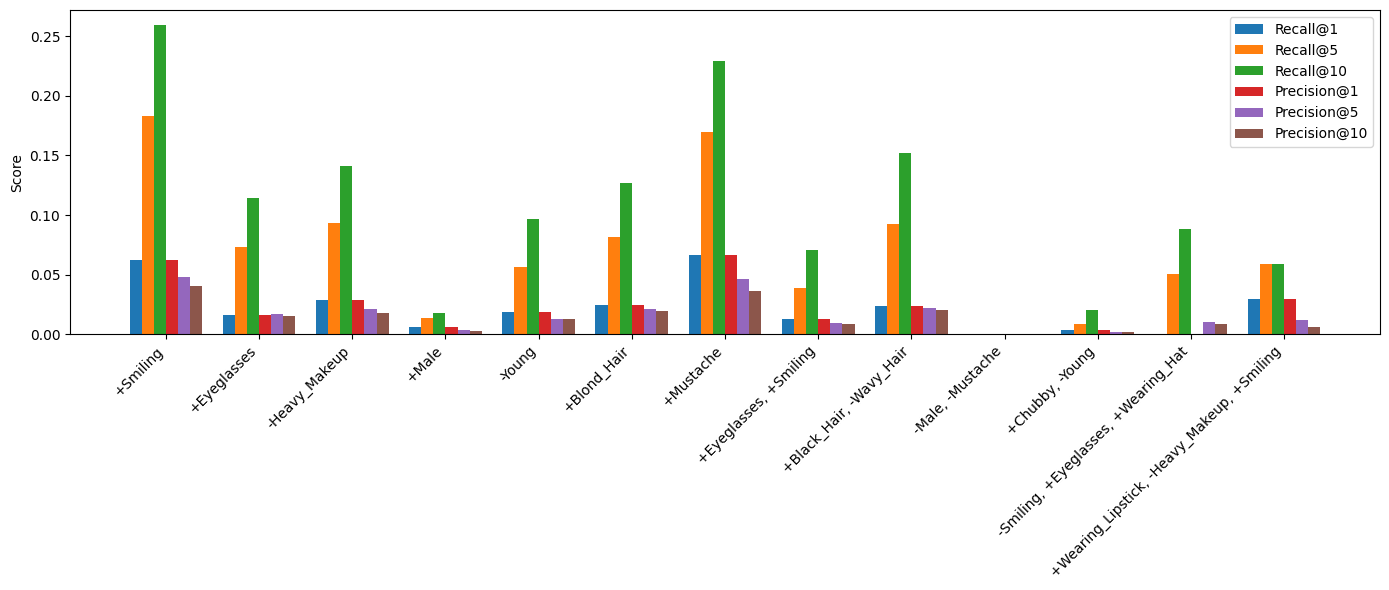

In [58]:
visualize_results()

- `-Male, -Mustache`: 0 hits across the board. small gt pool (27 src imgs)? or double -ve breaking the arithmetic? or both attrs pushing same direction (redundancy)?
- `+Mustache` vs `+Male`: both signal masculine features but mustache does way better. why?
- `+Chubby, -Young`: near zero. rare attribute + negative combo. how often does it actually appear in data?
- precision values tiny across the board (<0.07). large gt lists explain some of it, but possibly also a sign naive composition is fundamentally weak
- single +ve attrs outperform multi-attr queries. stacking conditions breaks naive arithmetic. this is exactly what threads 2 & 4 should fix

## Thread 4: CLAY sign-aware subspaces

This section rewrites the baseline notebook for **Thread 4** in a cleaner report-ready format.

We build separate CLAY-style textual subspaces for:

- positive constraints
- negative constraints

Then we evaluate two training-free scoring rules:

- **CLAY-B1 additive**: reward positive alignment and penalize negative alignment
- **CLAY-B2 null-space**: remove the negative subspace, then retrieve through the positive one


### 1. Configuration

We keep the Thread 4 hyperparameters in one place so they are easy to tune on Colab without editing the retrieval code.


In [59]:
THREAD4_CFG = {
    "prompt_templates_positive": [
        "a portrait of a person with {attr}",
        "a face with {attr}",
        "a photo of a person showing {attr}",
        "a headshot of a person characterized by {attr}",
    ],
    "prompt_templates_negative": [
        "a portrait of a person without {attr}",
        "a face without {attr}",
        "a photo of a person not showing {attr}",
        "a headshot of a person characterized by the absence of {attr}",
    ],
    "svd_energy": 0.9,
    "max_rank": 4,
    "negative_lambda": 0.2,
    "negative_eta": 0.35,
    "reference_weight": 0.55,
    "baseline_weight": 0.30,
    "subspace_weight": 0.15,
    "qualitative_k": 5,
    "db_chunk_size": 1024,
    "sweep_negative_lambda": [0.1, 0.2, 0.35, 0.5],
    "sweep_negative_eta": [0.15, 0.35, 0.6],
    "sweep_svd_energy": [0.85, 0.9, 0.95],
    "sweep_max_rank": [2, 4],
    "sweep_refs_per_query": 12,
}

THREAD4_CFG


{'prompt_templates_positive': ['a portrait of a person with {attr}',
  'a face with {attr}',
  'a photo of a person showing {attr}',
  'a headshot of a person characterized by {attr}'],
 'prompt_templates_negative': ['a portrait of a person without {attr}',
  'a face without {attr}',
  'a photo of a person not showing {attr}',
  'a headshot of a person characterized by the absence of {attr}'],
 'svd_energy': 0.9,
 'max_rank': 4,
 'negative_lambda': 0.2,
 'negative_eta': 0.35,
 'reference_weight': 0.55,
 'baseline_weight': 0.3,
 'subspace_weight': 0.15,
 'qualitative_k': 5,
 'db_chunk_size': 1024,
 'sweep_negative_lambda': [0.1, 0.2, 0.35, 0.5],
 'sweep_negative_eta': [0.15, 0.35, 0.6],
 'sweep_svd_energy': [0.85, 0.9, 0.95],
 'sweep_max_rank': [2, 4],
 'sweep_refs_per_query': 12}

### 2. Prompt parsing and text embedding helpers

These helpers:

1. split each benchmark query into positive and negative attribute lists
2. convert CelebA attribute names into readable text
3. embed prompt variants with the CLIP text tower

Using multiple prompt templates makes the text subspace a small set of related textual directions instead of a single attribute vector.


In [60]:
def parse_annotation_query(query_text):
    positives, negatives = [], []
    for token in [part.strip() for part in query_text.split(",") if part.strip()]:
        if token.startswith("+"):
            positives.append(token[1:])
        elif token.startswith("-"):
            negatives.append(token[1:])
        else:
            raise ValueError(f"Unexpected query token: {token}")
    return positives, negatives


def attr_to_phrase(attr_name):
    return attr_name.replace("_", " ").lower()


def embed_prompt_list(prompts, batch_size=32):
    batches = []
    for start in range(0, len(prompts), batch_size):
        text_batch = prompts[start : start + batch_size]
        inputs = processor(text=text_batch, return_tensors="pt", padding=True, truncation=True)
        text_inputs = {key: value.to(DEVICE) for key, value in inputs.items()}
        batches.append(embed_text_batch(text_inputs))
    return torch.cat(batches, dim=0)


thread4_prompt_cache = {}


def get_attribute_prompt_embeddings(attribute, polarity):
    cache_key = (attribute, polarity)
    if cache_key in thread4_prompt_cache:
        return thread4_prompt_cache[cache_key]

    templates = (
        THREAD4_CFG["prompt_templates_positive"]
        if polarity == "positive"
        else THREAD4_CFG["prompt_templates_negative"]
    )
    prompts = [template.format(attr=attr_to_phrase(attribute)) for template in templates]
    embeddings = embed_prompt_list(prompts)
    thread4_prompt_cache[cache_key] = embeddings
    return embeddings


def gather_prompt_bank(attributes, polarity):
    if not attributes:
        return None
    return torch.cat([get_attribute_prompt_embeddings(attr, polarity) for attr in attributes], dim=0)


### 3. Manifold helpers on the unit sphere

CLIP embeddings are L2-normalized, so Thread 4 works on the unit hypersphere.

- `spherical_log_map` moves prompt embeddings into the tangent space at the reference image
- `spherical_exp_map` maps a tangent-space direction back onto the sphere
- `choose_rank` keeps only the leading singular directions needed to explain most of the tangent-space energy


In [61]:
def normalize_rows(x):
    return F.normalize(x, p=2, dim=-1)


def spherical_log_map(base, points, eps=1e-6):
    base = normalize_rows(base.reshape(1, -1))
    points = normalize_rows(points)
    cosine = (points * base).sum(dim=-1, keepdim=True).clamp(-1 + eps, 1 - eps)
    tangent = points - cosine * base
    tangent_norm = tangent.norm(dim=-1, keepdim=True).clamp_min(eps)
    theta = torch.acos(cosine)
    return theta * tangent / tangent_norm


def spherical_exp_map(base, tangent, eps=1e-6):
    base = normalize_rows(base.reshape(1, -1))
    tangent_norm = tangent.norm(dim=-1, keepdim=True)
    safe_norm = tangent_norm.clamp_min(eps)
    direction = tangent / safe_norm
    lifted = torch.cos(tangent_norm) * base + torch.sin(tangent_norm) * direction
    lifted = torch.where(tangent_norm <= eps, base.expand_as(lifted), lifted)
    return normalize_rows(lifted)


def choose_rank(singular_values, energy=0.9, max_rank=4):
    if singular_values.numel() == 0:
        return 0
    power = singular_values.square()
    cumulative = torch.cumsum(power, dim=0) / power.sum()
    rank = int(torch.searchsorted(cumulative, energy).item()) + 1
    return max(1, min(rank, max_rank, singular_values.numel()))


### 4. Building positive and negative CLAY subspaces

For each query and reference image:

1. embed the positive prompt set
2. embed the negative prompt set
3. map both sets into the tangent space at the reference image
4. run SVD separately
5. keep the leading singular vectors as subspace bases

This cell also defines chunked scoring helpers so the full evaluation does **not** run out of GPU memory.


In [62]:
def build_tangent_subspace(base, prompt_embeddings, energy=0.9, max_rank=4):
    dim = base.numel()
    if prompt_embeddings is None or prompt_embeddings.numel() == 0:
        return {
            "rank": 0,
            "basis": torch.zeros((0, dim), device=base.device, dtype=base.dtype),
            "projector": torch.zeros((dim, dim), device=base.device, dtype=base.dtype),
            "mean_tangent": torch.zeros((1, dim), device=base.device, dtype=base.dtype),
            "singular_values": torch.zeros(0, device=base.device, dtype=base.dtype),
        }

    tangent_vectors = spherical_log_map(base, prompt_embeddings)
    _, singular_values, vh = torch.linalg.svd(tangent_vectors, full_matrices=False)
    rank = choose_rank(singular_values, energy=energy, max_rank=max_rank)
    basis = vh[:rank]
    projector = basis.T @ basis
    mean_tangent = tangent_vectors.mean(dim=0, keepdim=True)
    return {
        "rank": rank,
        "basis": basis,
        "projector": projector,
        "mean_tangent": mean_tangent,
        "singular_values": singular_values,
    }



def build_query_subspaces(ref_embedding, positive_attributes, negative_attributes, energy=None, max_rank=None):
    if energy is None:
        energy = THREAD4_CFG["svd_energy"]
    if max_rank is None:
        max_rank = THREAD4_CFG["max_rank"]

    positive_prompts = gather_prompt_bank(positive_attributes, "positive")
    negative_prompts = gather_prompt_bank(negative_attributes, "negative")

    positive_subspace = build_tangent_subspace(
        ref_embedding,
        positive_prompts,
        energy=energy,
        max_rank=max_rank,
    )
    negative_subspace = build_tangent_subspace(
        ref_embedding,
        negative_prompts,
        energy=energy,
        max_rank=max_rank,
    )
    return positive_subspace, negative_subspace



def project_rows(vectors, projector):
    projected = vectors @ projector
    norms = projected.norm(dim=-1, keepdim=True).clamp_min(1e-8)
    return projected / norms



def projection_norms(vectors, projector):
    return (vectors @ projector).norm(dim=-1)



def iter_db_chunks(db, chunk_size=None):
    if chunk_size is None:
        chunk_size = THREAD4_CFG["db_chunk_size"]
    for start in range(0, len(db), chunk_size):
        yield start, db[start : start + chunk_size]



def topk_from_scores(scores, ref_idx, k=10):
    scores = scores.clone()
    scores[ref_idx] = -float("inf")
    return torch.topk(scores, k=k, largest=True).indices.tolist()



def compose_baseline_query(ref_embedding, positive_attributes, negative_attributes):
    query = ref_embedding.reshape(1, -1) + sum_up(positive_attributes) - sum_up(negative_attributes)
    return normalize_rows(query)



def resolve_thread4_params(params=None):
    params = {} if params is None else dict(params)
    return {
        "negative_lambda": params.get("negative_lambda", THREAD4_CFG["negative_lambda"]),
        "negative_eta": params.get("negative_eta", THREAD4_CFG["negative_eta"]),
        "reference_weight": params.get("reference_weight", THREAD4_CFG["reference_weight"]),
        "baseline_weight": params.get("baseline_weight", THREAD4_CFG["baseline_weight"]),
        "subspace_weight": params.get("subspace_weight", THREAD4_CFG["subspace_weight"]),
        "svd_energy": params.get("svd_energy", THREAD4_CFG["svd_energy"]),
        "max_rank": params.get("max_rank", THREAD4_CFG["max_rank"]),
    }



def score_b1_chunk(chunk, ref_embedding, baseline_query, query, pos_subspace, neg_subspace, params):
    ref_scores = (chunk @ ref_embedding.reshape(-1, 1)).squeeze(-1)
    baseline_scores = (chunk @ baseline_query.T).squeeze(-1)

    if pos_subspace["rank"] > 0:
        positive_component = chunk @ pos_subspace["projector"]
        positive_scores = (positive_component @ query.T).squeeze(-1)
    else:
        positive_scores = torch.zeros(chunk.shape[0], device=chunk.device, dtype=chunk.dtype)

    if neg_subspace["rank"] > 0:
        negative_component = chunk @ neg_subspace["projector"]
        negative_scores = (negative_component @ query.T).squeeze(-1)
    else:
        negative_scores = torch.zeros(chunk.shape[0], device=chunk.device, dtype=chunk.dtype)

    return (
        params["reference_weight"] * ref_scores
        + params["baseline_weight"] * baseline_scores
        + params["subspace_weight"] * positive_scores
        - params["negative_lambda"] * negative_scores
    )



def score_b2_chunk(chunk, ref_embedding, baseline_query, positive_query, pos_subspace, neg_subspace, params):
    ref_scores = (chunk @ ref_embedding.reshape(-1, 1)).squeeze(-1)
    baseline_scores = (chunk @ baseline_query.T).squeeze(-1)

    transformed = chunk
    if neg_subspace["rank"] > 0:
        transformed = normalize_rows(transformed - params["negative_eta"] * (transformed @ neg_subspace["projector"]))
    if pos_subspace["rank"] > 0:
        positive_component = transformed @ pos_subspace["projector"]
        positive_scores = (positive_component @ positive_query.T).squeeze(-1)
    else:
        positive_scores = (transformed @ positive_query.T).squeeze(-1)

    return (
        params["reference_weight"] * ref_scores
        + params["baseline_weight"] * baseline_scores
        + params["subspace_weight"] * positive_scores
    )


### 5. Quick sanity check on one mixed-sign query

Before retrieving images, we inspect one real benchmark query and print the learned subspace ranks and singular values.


In [63]:
mixed_sign_annotation = next(
    annotation for annotation in annotations
    if "+" in annotation["query"] and "-" in annotation["query"]
)

mixed_pos, mixed_neg = parse_annotation_query(mixed_sign_annotation["query"])
mixed_ref_idx = int(next(iter(mixed_sign_annotation["ground_truth"].keys())))
mixed_params = resolve_thread4_params()
mixed_pos_subspace, mixed_neg_subspace = build_query_subspaces(
    img_db[mixed_ref_idx],
    mixed_pos,
    mixed_neg,
    energy=mixed_params["svd_energy"],
    max_rank=mixed_params["max_rank"],
)

print("Thread 4 demo query:", mixed_sign_annotation["query"])
print("positive attrs:", mixed_pos)
print("negative attrs:", mixed_neg)
print("current params:", mixed_params)
print("positive rank:", mixed_pos_subspace["rank"])
print("positive singular values:", mixed_pos_subspace["singular_values"][: mixed_pos_subspace["rank"]])
print("negative rank:", mixed_neg_subspace["rank"])
print("negative singular values:", mixed_neg_subspace["singular_values"][: mixed_neg_subspace["rank"]])


Thread 4 demo query: +Black_Hair, -Wavy_Hair
positive attrs: ['Black_Hair']
negative attrs: ['Wavy_Hair']
current params: {'negative_lambda': 0.2, 'negative_eta': 0.35, 'reference_weight': 0.55, 'baseline_weight': 0.3, 'subspace_weight': 0.15, 'svd_energy': 0.9, 'max_rank': 4}
positive rank: 1
positive singular values: tensor([2.6041], device='cuda:0')
negative rank: 1
negative singular values: tensor([2.5400], device='cuda:0')


### 6. Retrieval rules

We keep the baseline retrieval for comparison, then define the two CLAY variants.

The important implementation detail is that both CLAY variants score the database **chunk by chunk**, which avoids the GPU out-of-memory error from the previous version.


In [64]:
BEST_THREAD4_PARAMS = {
    "CLAY-B1 additive": resolve_thread4_params(),
    "CLAY-B2 null-space": resolve_thread4_params(),
}



def retrieve_baseline_thread4(ref_idx, positive_attributes, negative_attributes, k=10, params=None):
    query = compose_baseline_query(img_db[ref_idx], positive_attributes, negative_attributes)
    scores = (img_db @ query.T).squeeze(-1)
    return topk_from_scores(scores, ref_idx, k=k)



def retrieve_clay_b1(ref_idx, positive_attributes, negative_attributes, k=10, params=None):
    params = resolve_thread4_params(params)
    ref_embedding = img_db[ref_idx]
    baseline_query = compose_baseline_query(ref_embedding, positive_attributes, negative_attributes)
    pos_subspace, neg_subspace = build_query_subspaces(
        ref_embedding,
        positive_attributes,
        negative_attributes,
        energy=params["svd_energy"],
        max_rank=params["max_rank"],
    )
    combined_tangent = pos_subspace["mean_tangent"] - params["negative_lambda"] * neg_subspace["mean_tangent"]
    query = spherical_exp_map(ref_embedding, combined_tangent)

    score_chunks = []
    for _, chunk in iter_db_chunks(img_db):
        score_chunks.append(
            score_b1_chunk(chunk, ref_embedding, baseline_query, query, pos_subspace, neg_subspace, params).detach().cpu()
        )

    scores = torch.cat(score_chunks, dim=0).to(img_db.device)
    return topk_from_scores(scores, ref_idx, k=k)



def retrieve_clay_b2(ref_idx, positive_attributes, negative_attributes, k=10, params=None):
    params = resolve_thread4_params(params)
    ref_embedding = img_db[ref_idx]
    baseline_query = compose_baseline_query(ref_embedding, positive_attributes, negative_attributes)
    pos_subspace, neg_subspace = build_query_subspaces(
        ref_embedding,
        positive_attributes,
        negative_attributes,
        energy=params["svd_energy"],
        max_rank=params["max_rank"],
    )

    if pos_subspace["rank"] > 0:
        positive_query = spherical_exp_map(ref_embedding, pos_subspace["mean_tangent"])
    else:
        positive_query = baseline_query

    score_chunks = []
    for _, chunk in iter_db_chunks(img_db):
        score_chunks.append(
            score_b2_chunk(chunk, ref_embedding, baseline_query, positive_query, pos_subspace, neg_subspace, params).detach().cpu()
        )

    scores = torch.cat(score_chunks, dim=0).to(img_db.device)
    return topk_from_scores(scores, ref_idx, k=k)



def retrieve_clay_b1_best(ref_idx, positive_attributes, negative_attributes, k=10, params=None):
    active = BEST_THREAD4_PARAMS["CLAY-B1 additive"] if params is None else params
    return retrieve_clay_b1(ref_idx, positive_attributes, negative_attributes, k=k, params=active)



def retrieve_clay_b2_best(ref_idx, positive_attributes, negative_attributes, k=10, params=None):
    active = BEST_THREAD4_PARAMS["CLAY-B2 null-space"] if params is None else params
    return retrieve_clay_b2(ref_idx, positive_attributes, negative_attributes, k=k, params=active)


METHODS = {
    "Baseline arithmetic": retrieve_baseline_thread4,
    "CLAY-B1 additive": retrieve_clay_b1_best,
    "CLAY-B2 null-space": retrieve_clay_b2_best,
}

list(METHODS.keys())


['Baseline arithmetic', 'CLAY-B1 additive', 'CLAY-B2 null-space']

### 7. Qualitative retrieval visualization helpers

The next helper draws a clean comparison panel:

- reference image
- a few ground-truth targets
- top retrieved images for each method

Metrics are printed separately so the image output and the score output do not get mixed into one large cell result.


In [65]:
def collect_method_metrics(annotation, ref_idx, k=10):
    positive_attributes, negative_attributes = parse_annotation_query(annotation["query"])
    ground_truth = annotation["ground_truth"][str(ref_idx)]
    retrieved = {
        name: fn(ref_idx, positive_attributes, negative_attributes, k=k)
        for name, fn in METHODS.items()
    }
    metrics = {
        name: {
            cutoff: evaluate_retrieval(indices, ground_truth, cutoff, log=False)
            for cutoff in [1, 5, 10]
        }
        for name, indices in retrieved.items()
    }
    return retrieved, metrics, ground_truth


def show_retrieval_grid(annotation, ref_idx=None, k=None):
    if k is None:
        k = THREAD4_CFG["qualitative_k"]
    if ref_idx is None:
        ref_idx = int(next(iter(annotation["ground_truth"].keys())))

    retrieved, _, ground_truth = collect_method_metrics(annotation, ref_idx, k=max(k, 10))

    rows = [
        ("Reference", [ref_idx] + [None] * (k - 1)),
        ("Ground truth", ground_truth[:k] + [None] * max(0, k - len(ground_truth[:k]))),
    ]
    rows.extend((name, indices[:k]) for name, indices in retrieved.items())

    fig, axes = plt.subplots(len(rows), k, figsize=(3 * k, 2.8 * len(rows)))
    if len(rows) == 1:
        axes = np.expand_dims(axes, axis=0)
    if k == 1:
        axes = np.expand_dims(axes, axis=1)

    for row_idx, (row_name, image_indices) in enumerate(rows):
        for col_idx in range(k):
            ax = axes[row_idx, col_idx]
            image_idx = image_indices[col_idx] if col_idx < len(image_indices) else None
            if image_idx is None:
                ax.axis("off")
                continue
            ax.imshow(celeba[image_idx][0])
            ax.set_title(str(image_idx), fontsize=10)
            ax.axis("off")
        axes[row_idx, 0].set_ylabel(row_name, rotation=0, labelpad=55, va="center")

    plt.suptitle(f"Query: {annotation['query']} | ref={ref_idx}", y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()


def print_method_metrics(annotation, ref_idx=None, k=10):
    if ref_idx is None:
        ref_idx = int(next(iter(annotation["ground_truth"].keys())))

    _, metrics, _ = collect_method_metrics(annotation, ref_idx, k=k)
    print(f"Query: {annotation['query']} | ref={ref_idx}")
    print("-" * 80)
    for method_name, method_scores in metrics.items():
        print(method_name)
        for cutoff in [1, 5, 10]:
            print(f"  @ {cutoff}: {method_scores[cutoff]}")
        print("-" * 80)


### 8. Single-query qualitative example

We begin with one representative mixed-sign query to make the retrieval behavior easy to inspect before moving to the full benchmark. The figure below compares the baseline against both CLAY sign-aware variants on the same reference image.


In [66]:
demo_annotation = next(
    annotation for annotation in annotations
    if "+" in annotation["query"] and "-" in annotation["query"]
)
demo_ref_idx = int(next(iter(demo_annotation["ground_truth"].keys())))

demo_annotation["query"], demo_ref_idx


('+Black_Hair, -Wavy_Hair', 2)

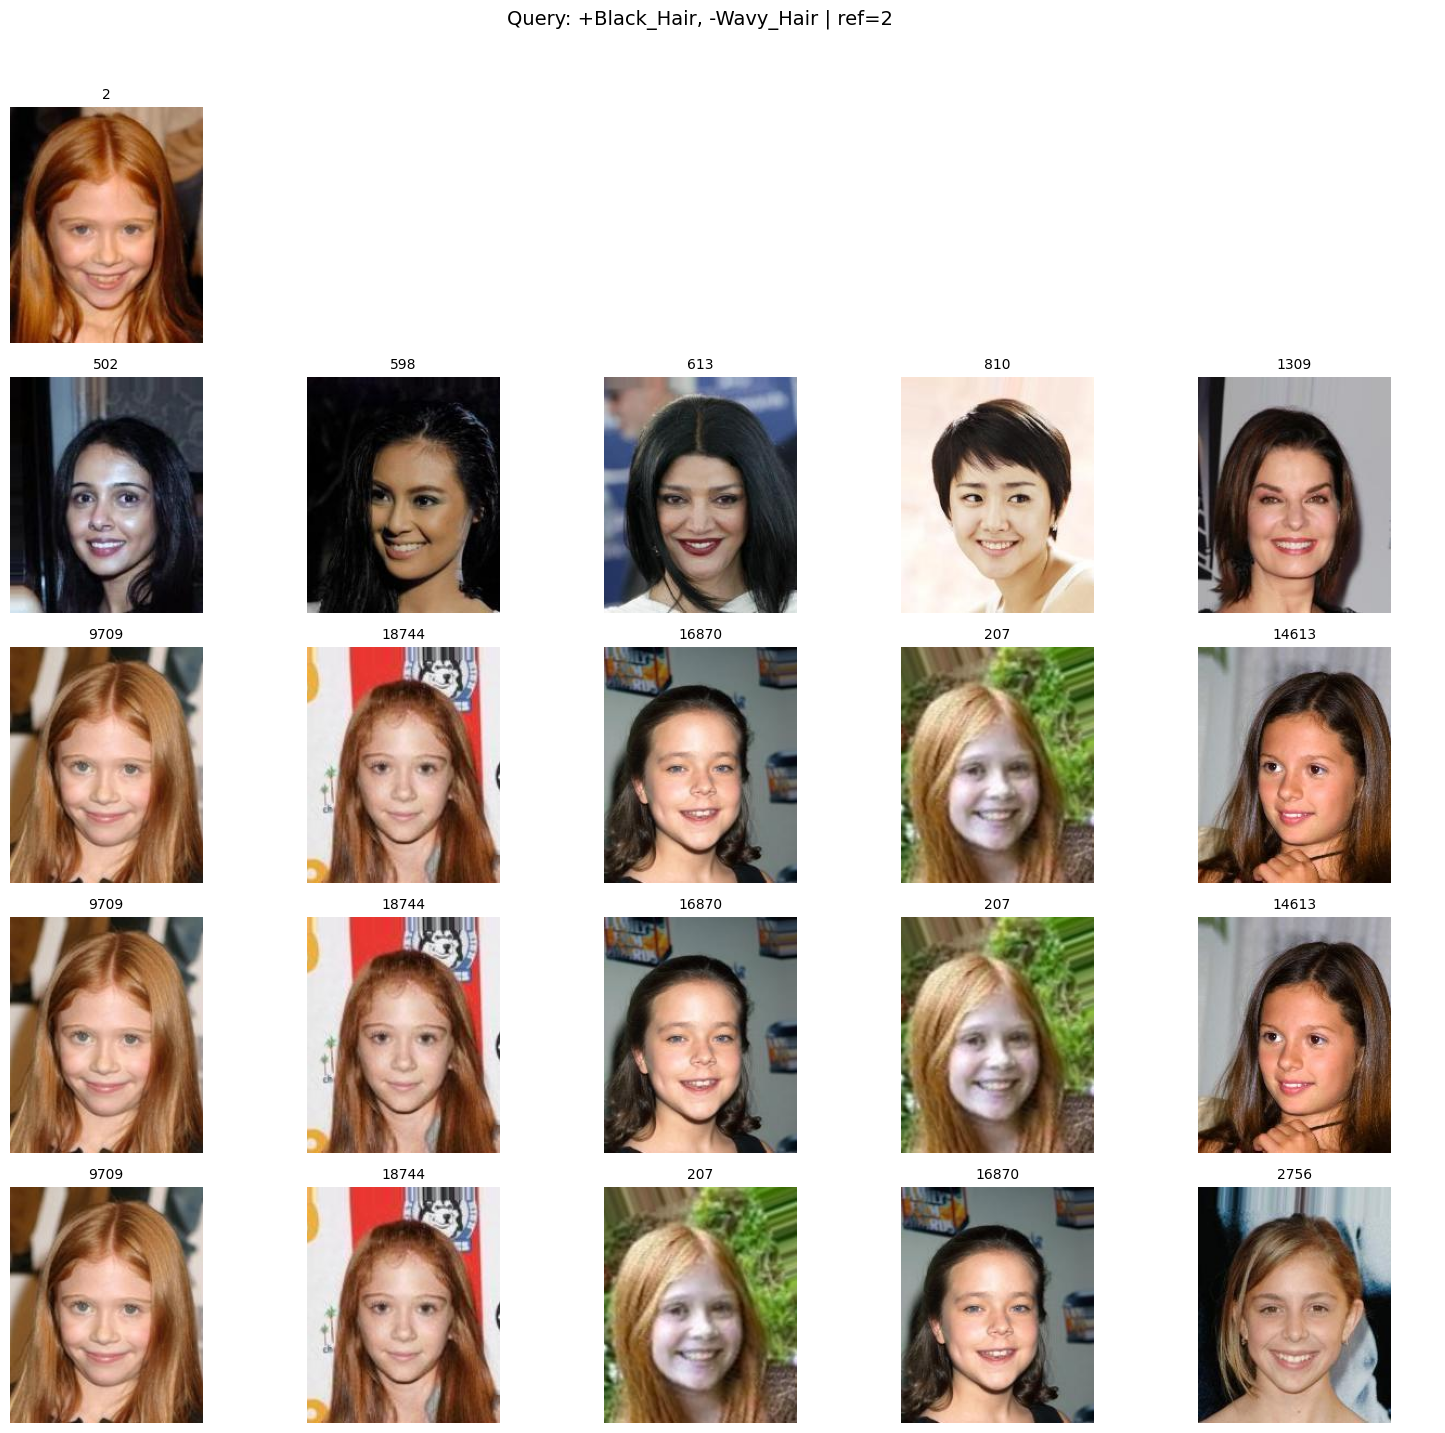

In [67]:
show_retrieval_grid(demo_annotation, ref_idx=demo_ref_idx, k=5)


In [68]:
print_method_metrics(demo_annotation, ref_idx=demo_ref_idx, k=10)


Query: +Black_Hair, -Wavy_Hair | ref=2
--------------------------------------------------------------------------------
Baseline arithmetic
  @ 1: {'Recall@1': 0, 'Precision@1': 0.0}
  @ 5: {'Recall@5': 0, 'Precision@5': 0.0}
  @ 10: {'Recall@10': 0, 'Precision@10': 0.0}
--------------------------------------------------------------------------------
CLAY-B1 additive
  @ 1: {'Recall@1': 0, 'Precision@1': 0.0}
  @ 5: {'Recall@5': 0, 'Precision@5': 0.0}
  @ 10: {'Recall@10': 0, 'Precision@10': 0.0}
--------------------------------------------------------------------------------
CLAY-B2 null-space
  @ 1: {'Recall@1': 0, 'Precision@1': 0.0}
  @ 5: {'Recall@5': 0, 'Precision@5': 0.0}
  @ 10: {'Recall@10': 0, 'Precision@10': 0.0}
--------------------------------------------------------------------------------


### 9. Subspace diagnostics

The next two figures explain the geometry behind Thread 4.

- The singular-value plots show whether the positive and negative prompt sets collapse to a small number of dominant directions.
- The projection-strength bars show how strongly the retrieved top-k images align with the positive and negative subspaces.

Together, these diagnostics help interpret whether the CLAY-style subspaces are producing useful structure or simply over-constraining retrieval.


In [69]:
def get_query_subspace_diagnostics(annotation, ref_idx=None):
    if ref_idx is None:
        ref_idx = int(next(iter(annotation["ground_truth"].keys())))

    positive_attributes, negative_attributes = parse_annotation_query(annotation["query"])
    pos_subspace, neg_subspace = build_query_subspaces(img_db[ref_idx], positive_attributes, negative_attributes)

    return {
        "query": annotation["query"],
        "ref_idx": ref_idx,
        "positive_attributes": positive_attributes,
        "negative_attributes": negative_attributes,
        "positive_subspace": pos_subspace,
        "negative_subspace": neg_subspace,
    }


def plot_subspace_singular_values(annotation, ref_idx=None):
    diagnostics = get_query_subspace_diagnostics(annotation, ref_idx=ref_idx)
    pos_sv = diagnostics["positive_subspace"]["singular_values"].detach().cpu().numpy()
    neg_sv = diagnostics["negative_subspace"]["singular_values"].detach().cpu().numpy()

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    values_and_titles = [
        (pos_sv, "Positive singular values", "tab:green"),
        (neg_sv, "Negative singular values", "tab:red"),
    ]

    for ax, (values, title, color) in zip(axes, values_and_titles):
        if len(values) == 0:
            ax.text(0.5, 0.5, "No subspace", ha="center", va="center")
            ax.set_axis_off()
            continue
        ax.plot(range(1, len(values) + 1), values, marker="o", color=color)
        ax.set_title(title)
        ax.set_xlabel("Component")
        ax.set_ylabel("Singular value")
        ax.grid(alpha=0.3)

    plt.suptitle(f"Subspace spectrum | {diagnostics['query']}")
    plt.tight_layout()
    plt.show()


def plot_projection_strengths(annotation, ref_idx=None, top_k=5):
    if ref_idx is None:
        ref_idx = int(next(iter(annotation["ground_truth"].keys())))

    positive_attributes, negative_attributes = parse_annotation_query(annotation["query"])
    pos_subspace, neg_subspace = build_query_subspaces(img_db[ref_idx], positive_attributes, negative_attributes)
    retrieved, _, _ = collect_method_metrics(annotation, ref_idx, k=max(top_k, 10))

    rows = []
    for method_name, indices in retrieved.items():
        batch = img_db[indices[:top_k]]
        positive_strength = (
            projection_norms(batch, pos_subspace["projector"]).mean().item()
            if pos_subspace["rank"] > 0 else 0.0
        )
        negative_strength = (
            projection_norms(batch, neg_subspace["projector"]).mean().item()
            if neg_subspace["rank"] > 0 else 0.0
        )
        rows.append((method_name, positive_strength, negative_strength))

    labels = [row[0] for row in rows]
    positive_vals = [row[1] for row in rows]
    negative_vals = [row[2] for row in rows]
    x = np.arange(len(labels))
    width = 0.35

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(x - width / 2, positive_vals, width, label="positive subspace", color="tab:green")
    ax.bar(x + width / 2, negative_vals, width, label="negative subspace", color="tab:red")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=15, ha="right")
    ax.set_ylabel("Mean projection norm over top-k results")
    ax.set_title(f"Retrieved-set alignment | {annotation['query']} | ref={ref_idx}")
    ax.legend()
    plt.tight_layout()
    plt.show()


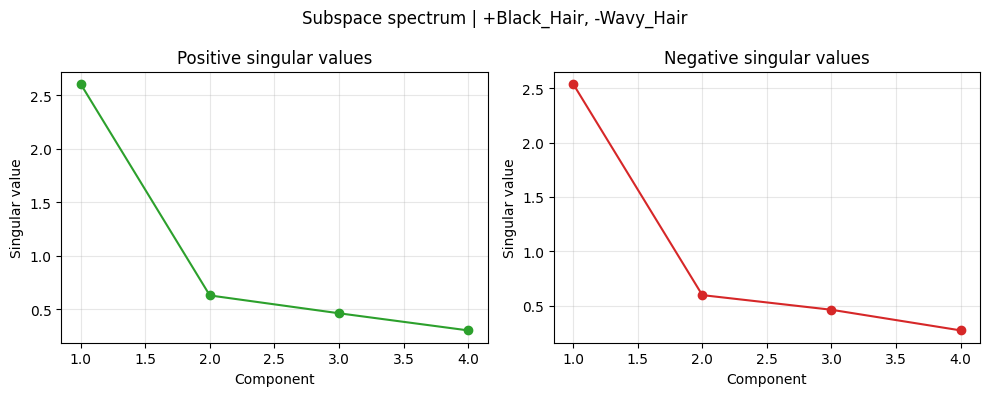

In [70]:
plot_subspace_singular_values(demo_annotation, ref_idx=demo_ref_idx)


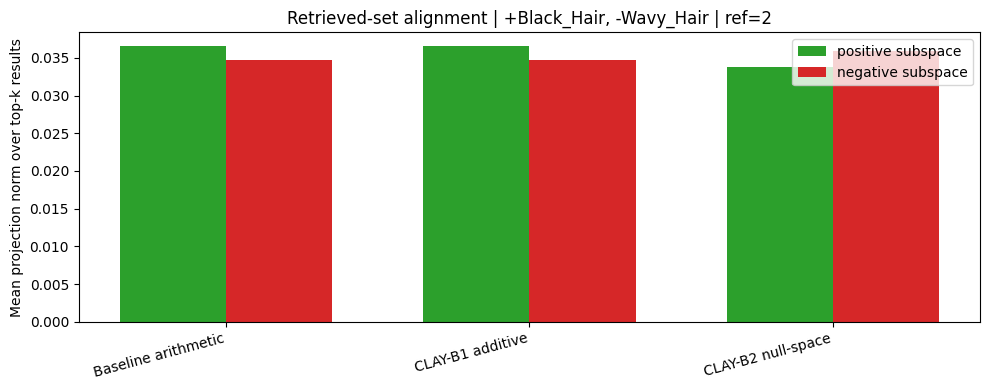

In [71]:
plot_projection_strengths(demo_annotation, ref_idx=demo_ref_idx, top_k=5)


### 10. Additional qualitative examples

To avoid over-interpreting a single query, we inspect three more mixed-sign benchmark queries. These are shown in separate cells so each query has its own image panel and its own metric printout.

Note that these examples intentionally exclude the demo query from the previous subsection.


In [72]:
mixed_sign_examples = [
    annotation for annotation in annotations
    if "+" in annotation["query"] and "-" in annotation["query"]
]

# Skip the first element because it is already used above as the demo query.
[annotation["query"] for annotation in mixed_sign_examples[1:6]]


['+Chubby, -Young',
 '-Smiling, +Eyeglasses, +Wearing_Hat',
 '+Wearing_Lipstick, -Heavy_Makeup, +Smiling']

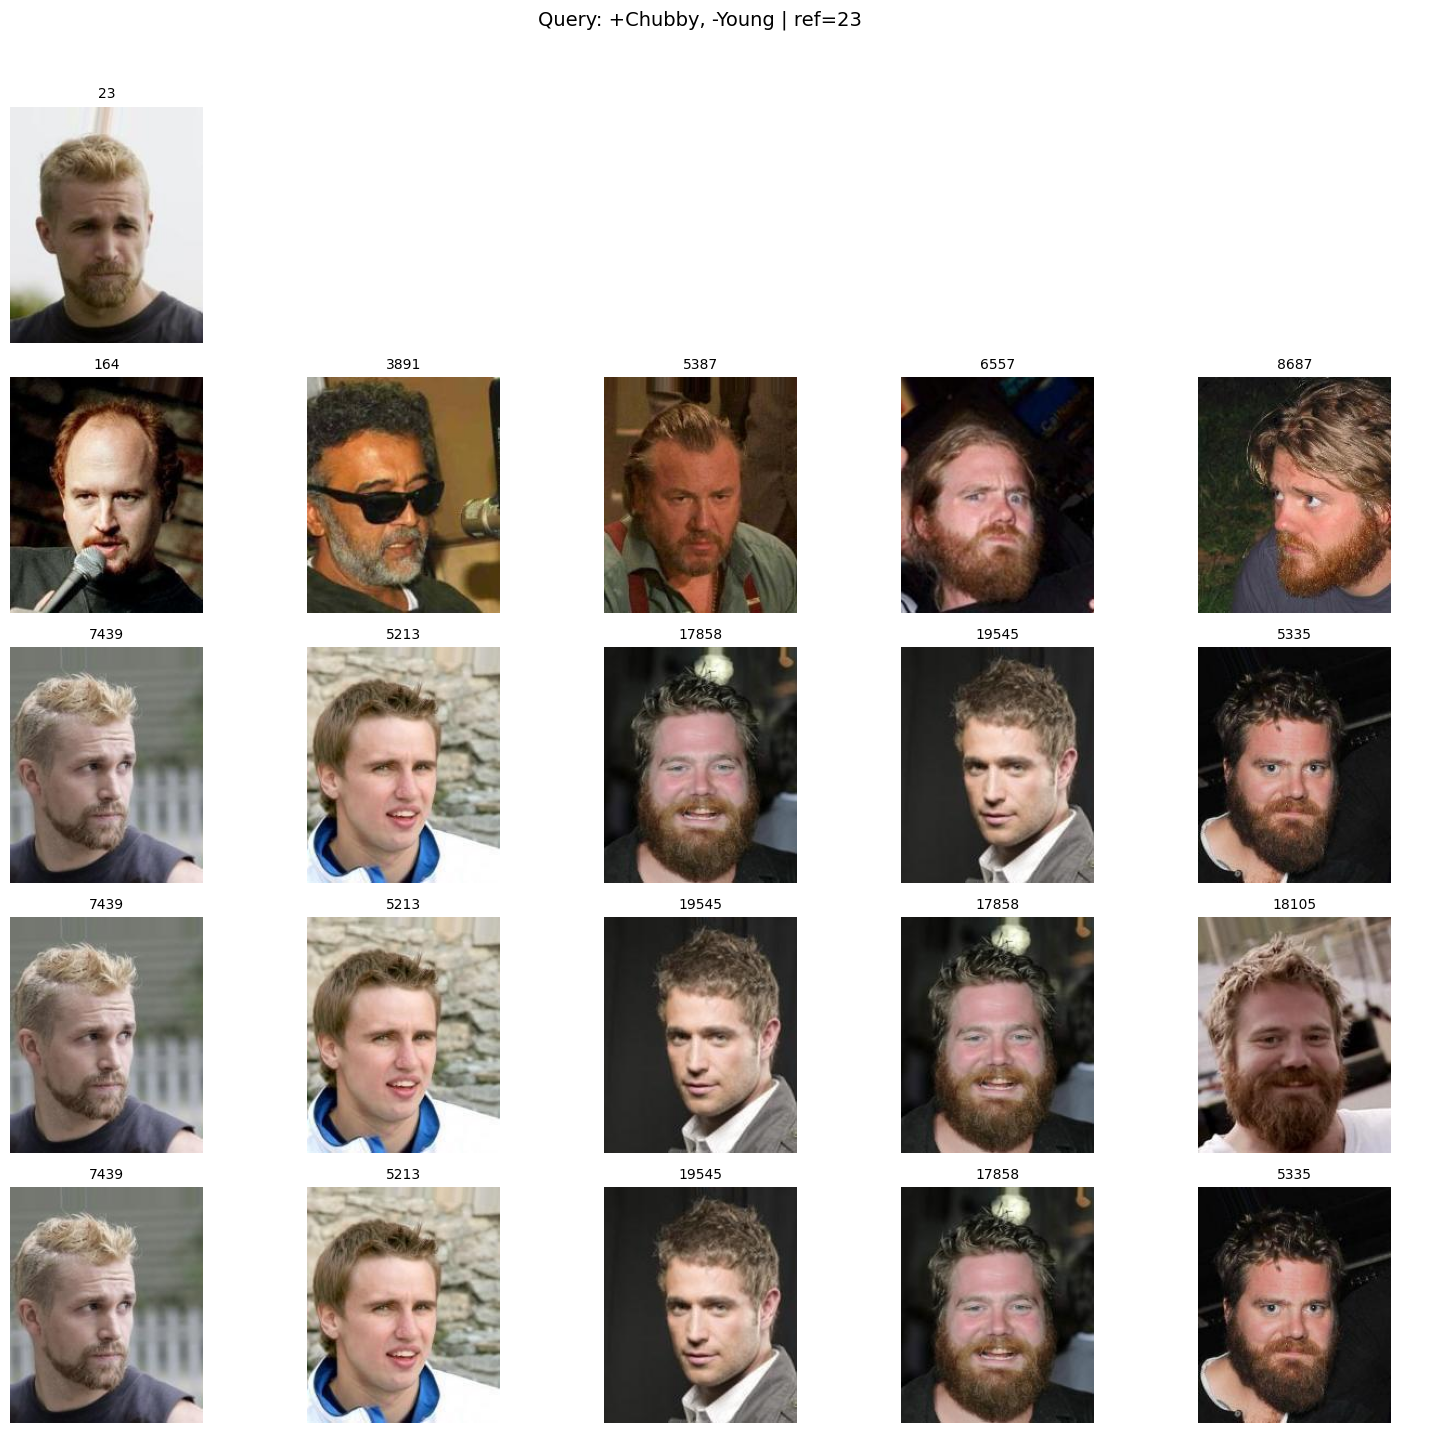

In [73]:
example_annotation_1 = mixed_sign_examples[1]
example_ref_idx_1 = int(next(iter(example_annotation_1["ground_truth"].keys())))
show_retrieval_grid(example_annotation_1, ref_idx=example_ref_idx_1, k=5)


In [74]:
print_method_metrics(example_annotation_1, ref_idx=example_ref_idx_1, k=10)


Query: +Chubby, -Young | ref=23
--------------------------------------------------------------------------------
Baseline arithmetic
  @ 1: {'Recall@1': 0, 'Precision@1': 0.0}
  @ 5: {'Recall@5': 0, 'Precision@5': 0.0}
  @ 10: {'Recall@10': 0, 'Precision@10': 0.0}
--------------------------------------------------------------------------------
CLAY-B1 additive
  @ 1: {'Recall@1': 0, 'Precision@1': 0.0}
  @ 5: {'Recall@5': 0, 'Precision@5': 0.0}
  @ 10: {'Recall@10': 0, 'Precision@10': 0.0}
--------------------------------------------------------------------------------
CLAY-B2 null-space
  @ 1: {'Recall@1': 0, 'Precision@1': 0.0}
  @ 5: {'Recall@5': 0, 'Precision@5': 0.0}
  @ 10: {'Recall@10': 0, 'Precision@10': 0.0}
--------------------------------------------------------------------------------


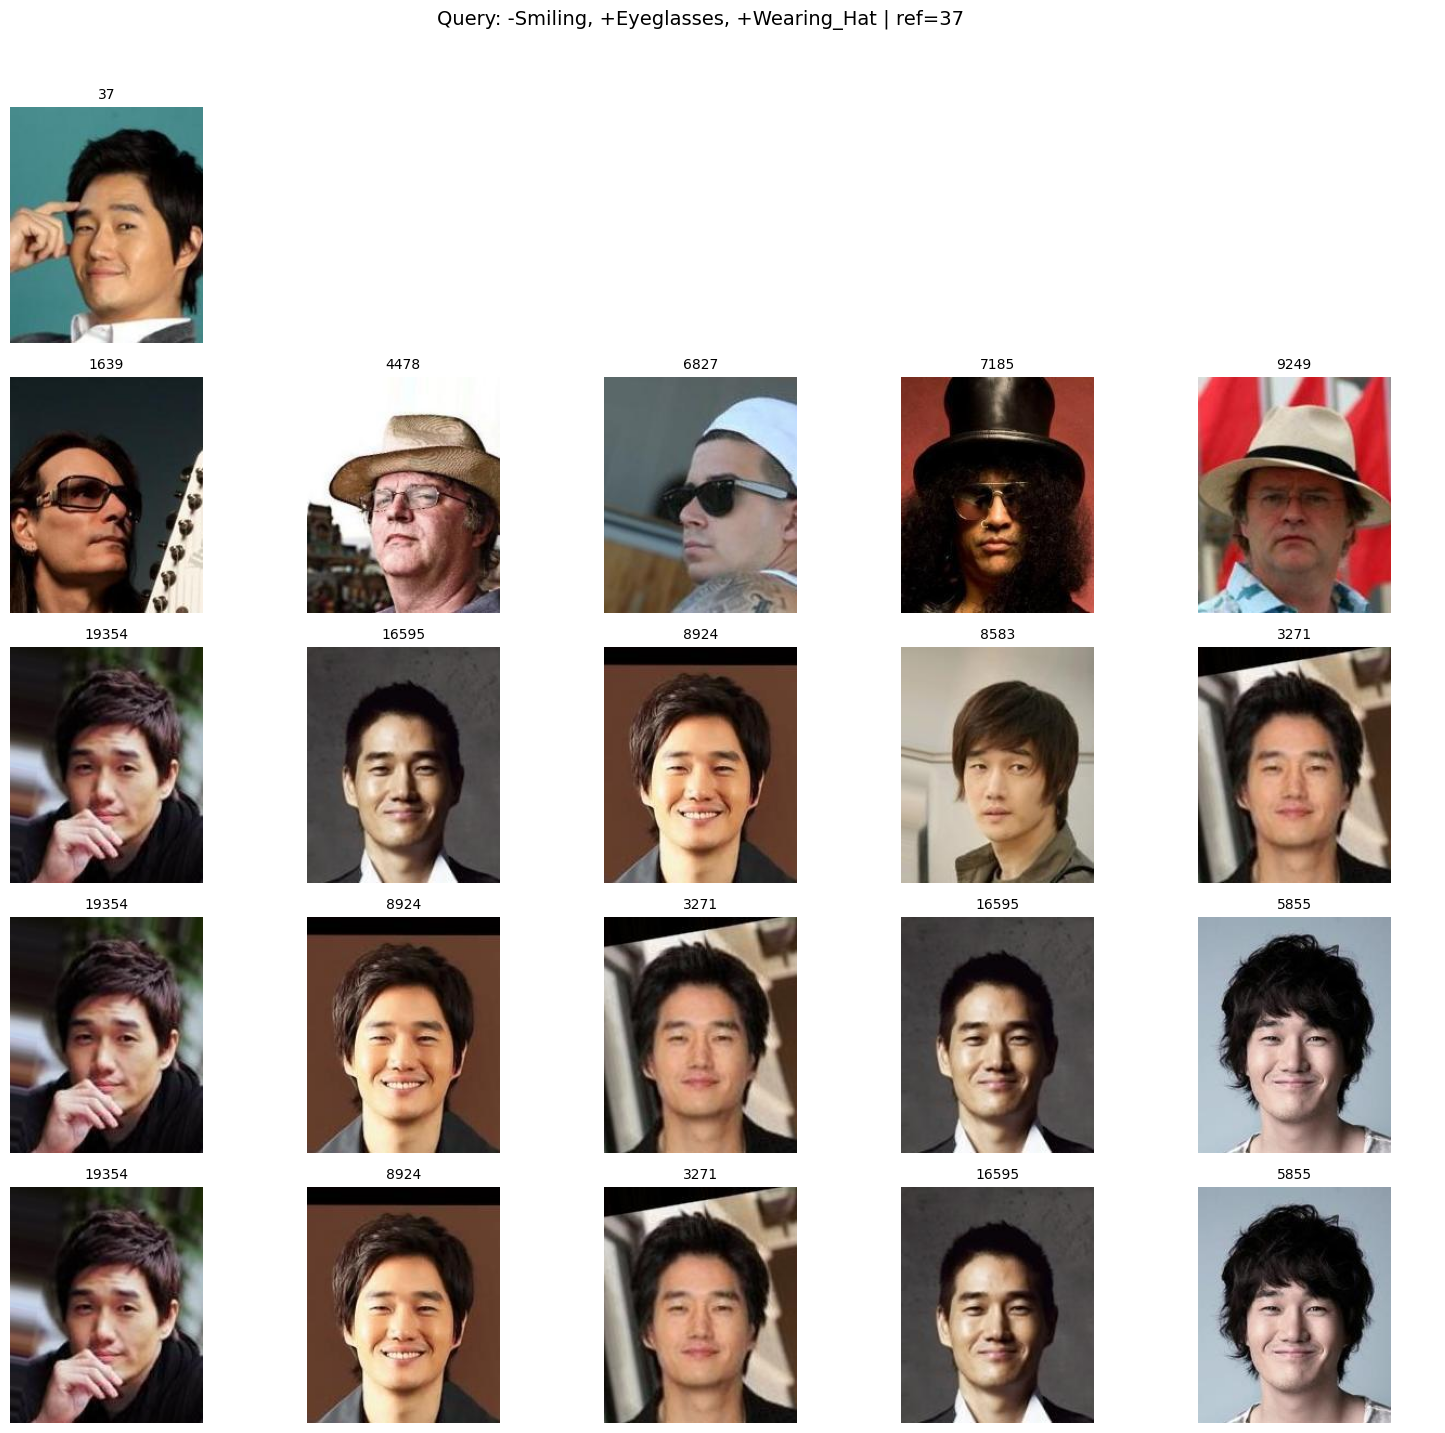

In [75]:
example_annotation_2 = mixed_sign_examples[2]
example_ref_idx_2 = int(next(iter(example_annotation_2["ground_truth"].keys())))
show_retrieval_grid(example_annotation_2, ref_idx=example_ref_idx_2, k=5)


In [76]:
print_method_metrics(example_annotation_2, ref_idx=example_ref_idx_2, k=10)


Query: -Smiling, +Eyeglasses, +Wearing_Hat | ref=37
--------------------------------------------------------------------------------
Baseline arithmetic
  @ 1: {'Recall@1': 0, 'Precision@1': 0.0}
  @ 5: {'Recall@5': 0, 'Precision@5': 0.0}
  @ 10: {'Recall@10': 1, 'Precision@10': 0.1}
--------------------------------------------------------------------------------
CLAY-B1 additive
  @ 1: {'Recall@1': 0, 'Precision@1': 0.0}
  @ 5: {'Recall@5': 0, 'Precision@5': 0.0}
  @ 10: {'Recall@10': 0, 'Precision@10': 0.0}
--------------------------------------------------------------------------------
CLAY-B2 null-space
  @ 1: {'Recall@1': 0, 'Precision@1': 0.0}
  @ 5: {'Recall@5': 0, 'Precision@5': 0.0}
  @ 10: {'Recall@10': 0, 'Precision@10': 0.0}
--------------------------------------------------------------------------------


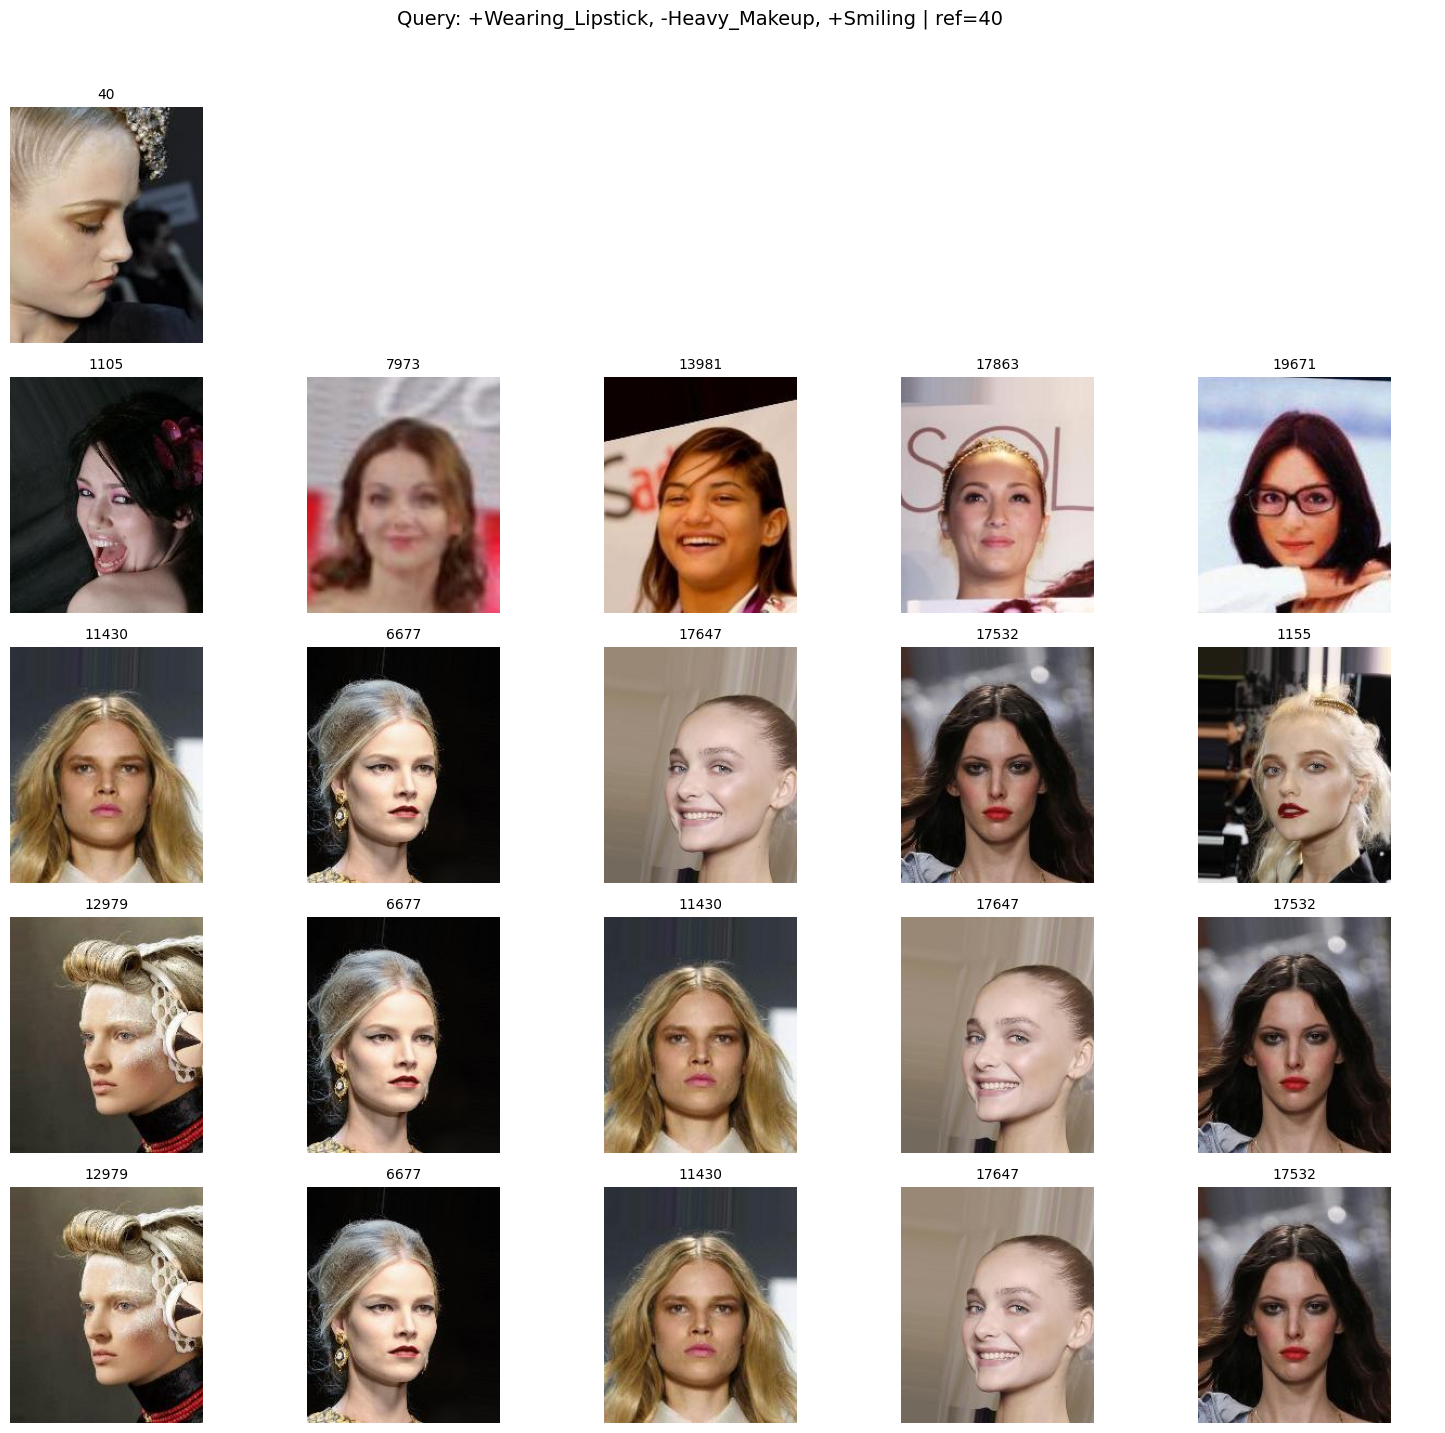

In [77]:
example_annotation_3 = mixed_sign_examples[3]
example_ref_idx_3 = int(next(iter(example_annotation_3["ground_truth"].keys())))
show_retrieval_grid(example_annotation_3, ref_idx=example_ref_idx_3, k=5)


In [78]:
print_method_metrics(example_annotation_3, ref_idx=example_ref_idx_3, k=10)


Query: +Wearing_Lipstick, -Heavy_Makeup, +Smiling | ref=40
--------------------------------------------------------------------------------
Baseline arithmetic
  @ 1: {'Recall@1': 0, 'Precision@1': 0.0}
  @ 5: {'Recall@5': 0, 'Precision@5': 0.0}
  @ 10: {'Recall@10': 0, 'Precision@10': 0.0}
--------------------------------------------------------------------------------
CLAY-B1 additive
  @ 1: {'Recall@1': 0, 'Precision@1': 0.0}
  @ 5: {'Recall@5': 0, 'Precision@5': 0.0}
  @ 10: {'Recall@10': 0, 'Precision@10': 0.0}
--------------------------------------------------------------------------------
CLAY-B2 null-space
  @ 1: {'Recall@1': 0, 'Precision@1': 0.0}
  @ 5: {'Recall@5': 0, 'Precision@5': 0.0}
  @ 10: {'Recall@10': 0, 'Precision@10': 0.0}
--------------------------------------------------------------------------------


### 11. Full Thread 4 evaluation

We now run the mandatory CelebA benchmark over all queries and report Recall@K and Precision@K at K = 1, 5, 10.

Before the final evaluation, the notebook performs a compact hyperparameter sweep for the two CLAY variants. The sweep tunes:

- negative penalty strength `negative_lambda`
- softened negative suppression `negative_eta`
- tangent-space subspace size via `svd_energy` and `max_rank`

The final benchmark then uses the best CLAY-B1 and CLAY-B2 settings found on the calibration subset.


In [79]:
def initialize_scores_table():
    return {
        annotation["query"]: {
            "ref_counts": len(annotation["ground_truth"]),
            "Recall@1": 0.0,
            "Recall@5": 0.0,
            "Recall@10": 0.0,
            "Precision@1": 0.0,
            "Precision@5": 0.0,
            "Precision@10": 0.0,
        }
        for annotation in annotations
    }



def compute_average_scores(score_table):
    averages = {}
    for query, values in score_table.items():
        count = values["ref_counts"]
        averages[query] = {
            metric: round(values[metric] / count, 4)
            for metric in ["Recall@1", "Recall@5", "Recall@10", "Precision@1", "Precision@5", "Precision@10"]
        }
    return averages



def evaluate_method(method_name, retrieval_fn, params=None, ref_limit_per_query=None):
    score_table = initialize_scores_table()
    for annotation in annotations:
        positive_attributes, negative_attributes = parse_annotation_query(annotation["query"])
        ref_indices = [int(idx) for idx in annotation["ground_truth"].keys()]
        if ref_limit_per_query is not None:
            ref_indices = ref_indices[:ref_limit_per_query]
            score_table[annotation["query"]]["ref_counts"] = len(ref_indices)

        for ref_idx in ref_indices:
            retrieved = retrieval_fn(ref_idx, positive_attributes, negative_attributes, k=10, params=params)
            ground_truth = annotation["ground_truth"][str(ref_idx)]

            for cutoff in [1, 5, 10]:
                result = evaluate_retrieval(retrieved, ground_truth, cutoff, log=False)
                for metric_name, metric_value in result.items():
                    score_table[annotation["query"]][metric_name] += metric_value

    return {
        "method": method_name,
        "raw": score_table,
        "averages": compute_average_scores(score_table),
    }



def aggregate_summary_from_payload(payload):
    averages_df = pd.DataFrame(payload["averages"]).T
    return {
        metric: round(averages_df[metric].mean(), 4)
        for metric in ["Recall@1", "Recall@5", "Recall@10", "Precision@1", "Precision@5", "Precision@10"]
    }



def build_sweep_grid():
    grid = []
    for negative_lambda in THREAD4_CFG["sweep_negative_lambda"]:
        for negative_eta in THREAD4_CFG["sweep_negative_eta"]:
            for svd_energy in THREAD4_CFG["sweep_svd_energy"]:
                for max_rank in THREAD4_CFG["sweep_max_rank"]:
                    grid.append({
                        "negative_lambda": negative_lambda,
                        "negative_eta": negative_eta,
                        "svd_energy": svd_energy,
                        "max_rank": max_rank,
                    })
    return grid



def tune_thread4_method(method_name, retrieval_fn):
    sweep_rows = []
    for candidate in build_sweep_grid():
        payload = evaluate_method(
            method_name,
            retrieval_fn,
            params=candidate,
            ref_limit_per_query=THREAD4_CFG["sweep_refs_per_query"],
        )
        summary = aggregate_summary_from_payload(payload)
        sweep_rows.append({
            "method": method_name,
            **candidate,
            **summary,
        })
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    sweep_df = pd.DataFrame(sweep_rows).sort_values(
        ["Recall@10", "Precision@10", "Recall@5"],
        ascending=False,
    ).reset_index(drop=True)
    best_row = sweep_df.iloc[0].to_dict()
    best_params = resolve_thread4_params(best_row)
    return best_params, sweep_df


In [80]:
thread4_tuning_results = {}

print("Tuning CLAY-B1 additive ...")
best_b1_params, b1_sweep_df = tune_thread4_method("CLAY-B1 additive", retrieve_clay_b1)
thread4_tuning_results["CLAY-B1 additive"] = b1_sweep_df
BEST_THREAD4_PARAMS["CLAY-B1 additive"] = best_b1_params
print("Best CLAY-B1 params:", best_b1_params)

print("Tuning CLAY-B2 null-space ...")
best_b2_params, b2_sweep_df = tune_thread4_method("CLAY-B2 null-space", retrieve_clay_b2)
thread4_tuning_results["CLAY-B2 null-space"] = b2_sweep_df
BEST_THREAD4_PARAMS["CLAY-B2 null-space"] = best_b2_params
print("Best CLAY-B2 params:", best_b2_params)

thread4_results = {}
for method_name, retrieval_fn in METHODS.items():
    print(f"Running {method_name} ...")
    thread4_results[method_name] = evaluate_method(method_name, retrieval_fn)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("Finished Thread 4 evaluation.")


Tuning CLAY-B1 additive ...
Best CLAY-B1 params: {'negative_lambda': 0.1, 'negative_eta': 0.15, 'reference_weight': 0.55, 'baseline_weight': 0.3, 'subspace_weight': 0.15, 'svd_energy': 0.85, 'max_rank': 2}
Tuning CLAY-B2 null-space ...
Best CLAY-B2 params: {'negative_lambda': 0.1, 'negative_eta': 0.35, 'reference_weight': 0.55, 'baseline_weight': 0.3, 'subspace_weight': 0.15, 'svd_energy': 0.85, 'max_rank': 2}
Running Baseline arithmetic ...
Running CLAY-B1 additive ...
Running CLAY-B2 null-space ...
Finished Thread 4 evaluation.


### 12. Quantitative result tables

We first display the best hyperparameters found for each CLAY variant, then the per-query benchmark table, and finally a compact summary averaged across all benchmark queries.

This makes it possible to see whether the hybrid scoring and softened negative suppression actually improve over the earlier Thread 4 version.


In [81]:
best_thread4_params_df = pd.DataFrame([
    {"method": method_name, **params}
    for method_name, params in BEST_THREAD4_PARAMS.items()
]).sort_values("method").reset_index(drop=True)

best_thread4_params_df


,method,negative_lambda,negative_eta,reference_weight,baseline_weight,subspace_weight,svd_energy,max_rank
0,CLAY-B1 additive,0.1,0.15,0.55,0.3,0.15,0.85,2
1,CLAY-B2 null-space,0.1,0.35,0.55,0.3,0.15,0.85,2


In [82]:
def results_to_frame(thread4_results):
    rows = []
    for method_name, payload in thread4_results.items():
        for query, metrics in payload["averages"].items():
            row = {"method": method_name, "query": query}
            row.update(metrics)
            rows.append(row)
    return pd.DataFrame(rows)


thread4_df = results_to_frame(thread4_results)
display(thread4_df.round(4))


,method,query,Recall@1,Recall@5,Recall@10,Precision@1,Precision@5,Precision@10
0,Baseline arithmetic,+Smiling,0.0623,0.1828,0.2591,0.0623,0.0479,0.0401
1,Baseline arithmetic,+Eyeglasses,0.0164,0.0733,0.1143,0.0164,0.0169,0.0153
2,Baseline arithmetic,-Heavy_Makeup,0.0286,0.0930,0.1414,0.0286,0.0215,0.0179
3,Baseline arithmetic,+Male,0.0063,0.0138,0.0182,0.0063,0.0036,0.0026
4,Baseline arithmetic,-Young,0.0190,0.0564,0.0971,0.0190,0.0132,0.0128
5,Baseline arithmetic,+Blond_Hair,0.0247,0.0819,0.1267,0.0247,0.0216,0.0193
6,Baseline arithmetic,+Mustache,0.0664,0.1694,0.2292,0.0664,0.0465,0.0365
7,Baseline arithmetic,"+Eyeglasses, +Smiling",0.0131,0.0392,0.0703,0.0131,0.0092,0.0085
8,Baseline arithmetic,"+Black_Hair, -Wavy_Hair",0.0237,0.0929,0.1520,0.0237,0.0219,0.0202
9,Baseline arithmetic,"-Male, -Mustache",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


### 13. Summary graphs

We first build the final method-level summary table, then visualize the tuned Thread 4 comparison from two perspectives:

- overall average performance across queries
- per-query performance differences between the baseline and the CLAY variants


In [83]:
summary_rows = []
for method_name in METHODS.keys():
    method_df = thread4_df[thread4_df["method"] == method_name]
    summary_rows.append({
        "method": method_name,
        **{
            metric: round(method_df[metric].mean(), 4)
            for metric in ["Recall@1", "Recall@5", "Recall@10", "Precision@1", "Precision@5", "Precision@10"]
        },
    })

thread4_summary = (
    pd.DataFrame(summary_rows)
    .sort_values("Recall@10", ascending=False)
    .reset_index(drop=True)
)

thread4_summary


def plot_thread4_summary(summary_df):
    metrics = ["Recall@1", "Recall@5", "Recall@10", "Precision@1", "Precision@5", "Precision@10"]
    x = np.arange(len(summary_df))
    width = 0.12

    fig, ax = plt.subplots(figsize=(14, 6))
    for idx, metric in enumerate(metrics):
        ax.bar(x + idx * width, summary_df[metric], width, label=metric)

    ax.set_xticks(x + width * (len(metrics) - 1) / 2)
    ax.set_xticklabels(summary_df["method"], rotation=15, ha="right")
    ax.set_ylabel("Average score across queries")
    ax.set_title("Thread 4 comparison after hybrid scoring + hyperparameter tuning")
    ax.legend(ncol=3)
    plt.tight_layout()
    plt.show()



def plot_per_query_metric(thread4_df, metric="Recall@10"):
    pivot = thread4_df.pivot(index="query", columns="method", values=metric)
    pivot.plot(kind="bar", figsize=(16, 6))
    plt.ylabel(metric)
    plt.title(f"Per-query comparison for {metric}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


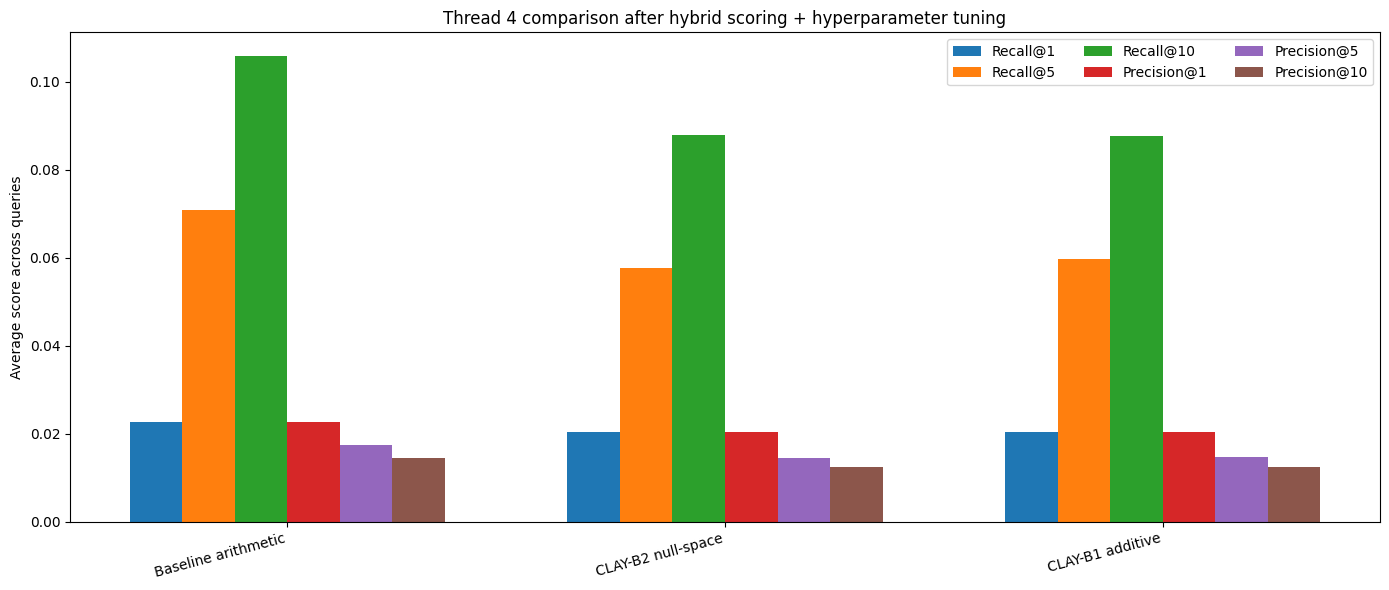

In [84]:
plot_thread4_summary(thread4_summary)


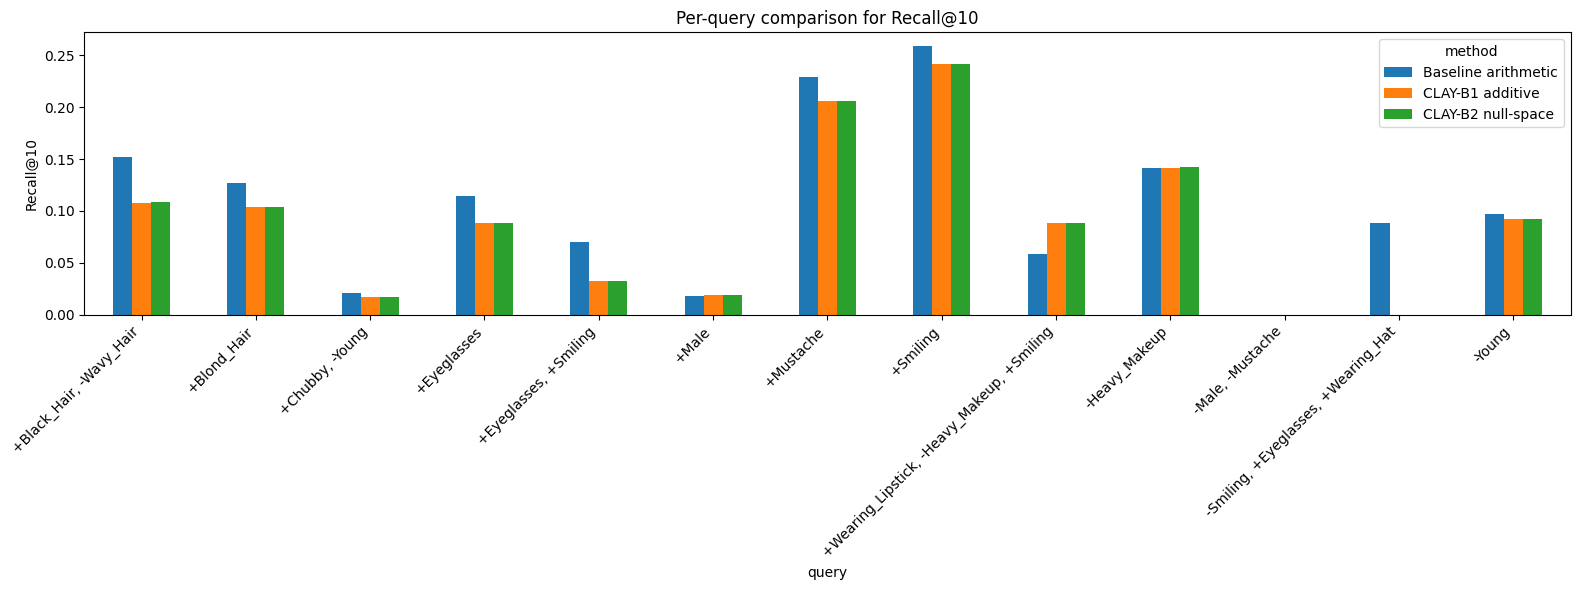

In [85]:
plot_per_query_metric(thread4_df, metric="Recall@10")


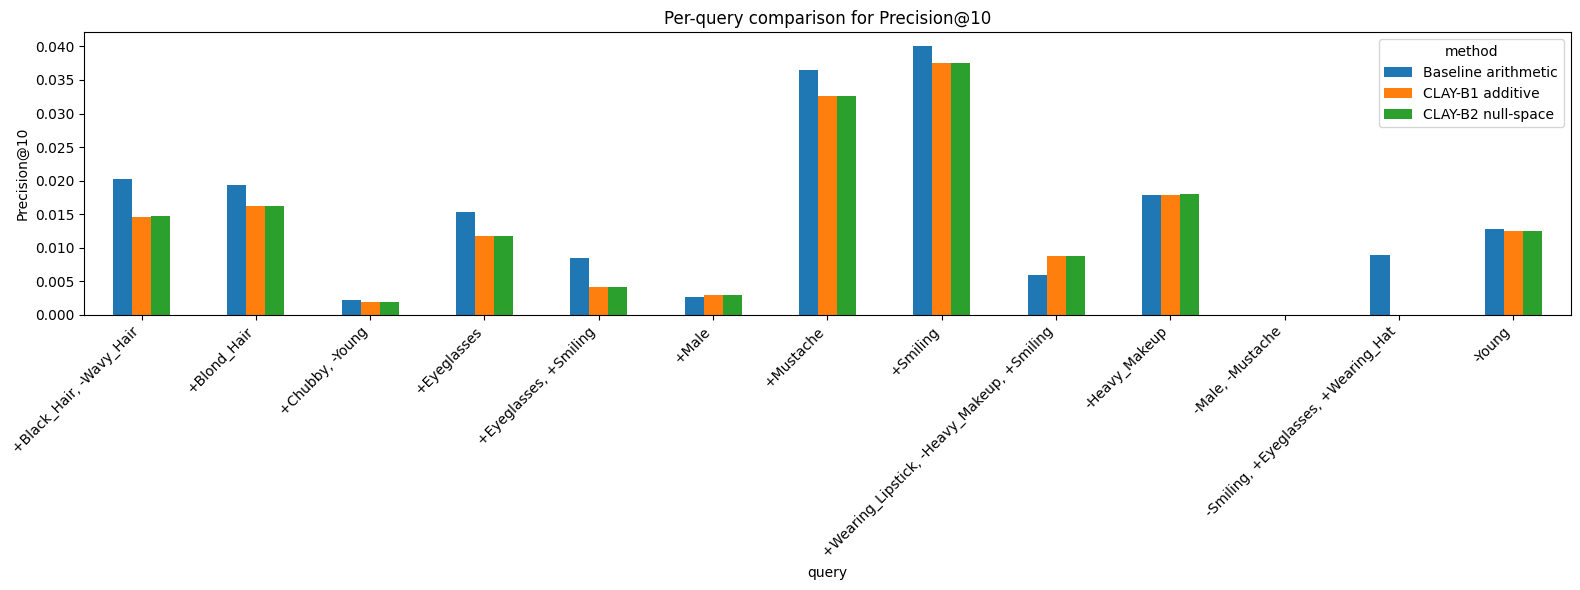

In [86]:
plot_per_query_metric(thread4_df, metric="Precision@10")


### 14. Heatmaps and query-level winners

The heatmaps make it easier to see where each method is strong or weak, while the winner table counts how often each method achieves the best Recall@10 across the benchmark queries.


In [87]:
def plot_metric_heatmap(thread4_df, metric="Recall@10"):
    pivot = thread4_df.pivot(index="query", columns="method", values=metric)
    fig, ax = plt.subplots(figsize=(10, 6))
    im = ax.imshow(pivot.values, aspect="auto", cmap="viridis")
    ax.set_xticks(np.arange(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=15, ha="right")
    ax.set_yticks(np.arange(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_title(f"Per-query heatmap for {metric}")
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(metric)
    plt.tight_layout()
    plt.show()


def summarize_query_winners(thread4_df, metric="Recall@10"):
    pivot = thread4_df.pivot(index="query", columns="method", values=metric)
    winners = pivot.idxmax(axis=1)
    winner_counts = winners.value_counts().rename_axis("method").reset_index(name="num_queries_won")
    display(winner_counts)
    return winners


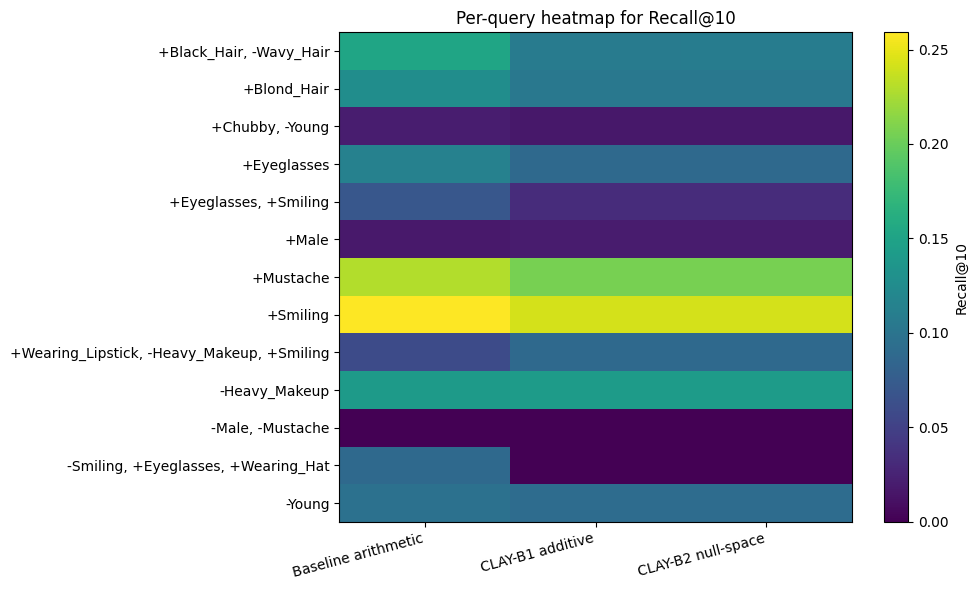

In [88]:
plot_metric_heatmap(thread4_df, metric="Recall@10")


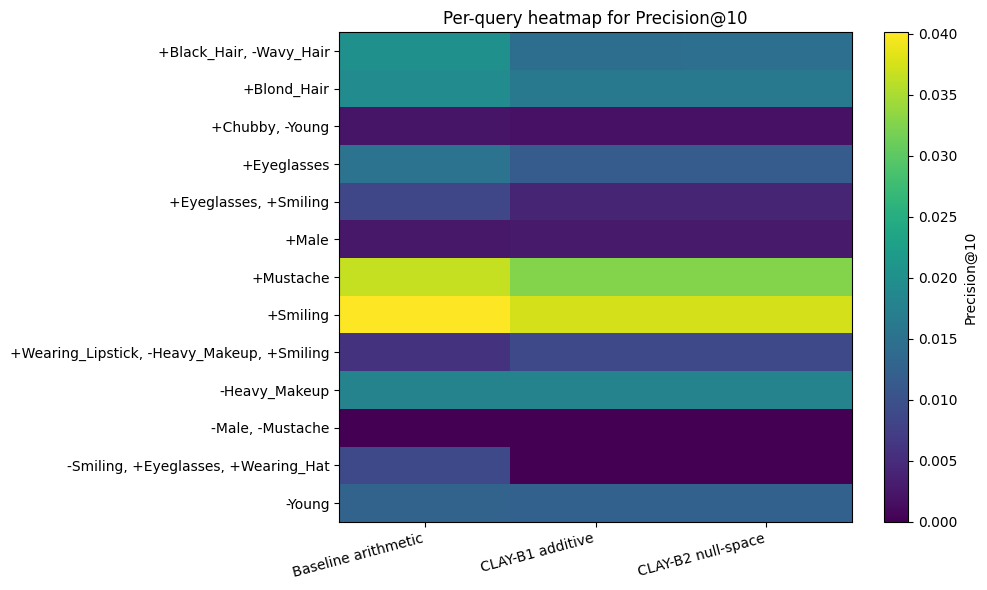

In [89]:
plot_metric_heatmap(thread4_df, metric="Precision@10")


In [90]:
query_winners = summarize_query_winners(thread4_df, metric="Recall@10")
query_winners


,method,num_queries_won
0,Baseline arithmetic,10
1,CLAY-B1 additive,2
2,CLAY-B2 null-space,1


,0
query,
"+Black_Hair, -Wavy_Hair",Baseline arithmetic
+Blond_Hair,Baseline arithmetic
"+Chubby, -Young",Baseline arithmetic
+Eyeglasses,Baseline arithmetic
"+Eyeglasses, +Smiling",Baseline arithmetic
+Male,CLAY-B1 additive
+Mustache,Baseline arithmetic
+Smiling,Baseline arithmetic
"+Wearing_Lipstick, -Heavy_Makeup, +Smiling",CLAY-B1 additive


### 15. Interpretation and conclusion

The tuned Thread 4 variants performed substantially better than the earlier untuned CLAY version, but they still did **not** surpass the baseline arithmetic composition overall.

The hyperparameter sweep selected compact and relatively conservative CLAY settings for both variants:

- **CLAY-B1 additive**: `negative_lambda = 0.1`, `negative_eta = 0.15`, `svd_energy = 0.85`, `max_rank = 2`
- **CLAY-B2 null-space**: `negative_lambda = 0.1`, `negative_eta = 0.35`, `svd_energy = 0.85`, `max_rank = 2`

These tuned settings are much less aggressive than the original Thread 4 setup. This is already informative: the best-performing CLAY variants on CelebA are the ones that keep more of the reference-image signal and apply weaker negative suppression.

From the final summary table:

- **Baseline arithmetic** remained the strongest method with `Recall@10 = 0.1059` and `Precision@10 = 0.0146`.
- **CLAY-B1 additive** improved to `Recall@10 = 0.0876` and `Precision@10 = 0.0124`.
- **CLAY-B2 null-space** improved to `Recall@10 = 0.0878` and `Precision@10 = 0.0124`.

Compared with the earlier untuned Thread 4 version, this is a large recovery: both CLAY variants moved from roughly `Recall@10 ≈ 0.024` to about `Recall@10 ≈ 0.088`. So the hybrid scoring, softened negative suppression, and parameter sweep clearly made the CLAY-style method much more competitive.

However, the winner analysis shows that the baseline still wins most of the benchmark queries: **10 of 13** for the baseline, versus **2 of 13** for **CLAY-B1** and **1 of 13** for **CLAY-B2**. This means the tuned CLAY variants are no longer collapsing, but they still do not consistently produce better rankings than the simpler arithmetic baseline.

The most reasonable interpretation is that CelebA rewards preserving the reference embedding very strongly. Once hybrid scoring explicitly reintroduces reference similarity, Thread 4 becomes much stronger, which supports the idea that the original CLAY-style projection was discarding too much identity information. At the same time, the fact that the baseline still wins overall suggests that these text-derived positive/negative subspaces are not yet reliable enough to improve retrieval across the full benchmark.

Therefore, the conclusion for Thread 4 is mixed but meaningful:

- the original CLAY-style sign-aware subspace formulation was too restrictive
- the improved hybrid version is much better and closes most of the gap
- but on this benchmark, **naive CLIP arithmetic still remains the best overall method**

This is still a valid project outcome, because it isolates an important lesson: sign-aware conditioning helps only when it is combined with strong reference retention and careful regularization. A stronger next step would likely be to combine Thread 4 with Thread 2's image-derived geodesic directions rather than relying only on text-derived subspaces.
